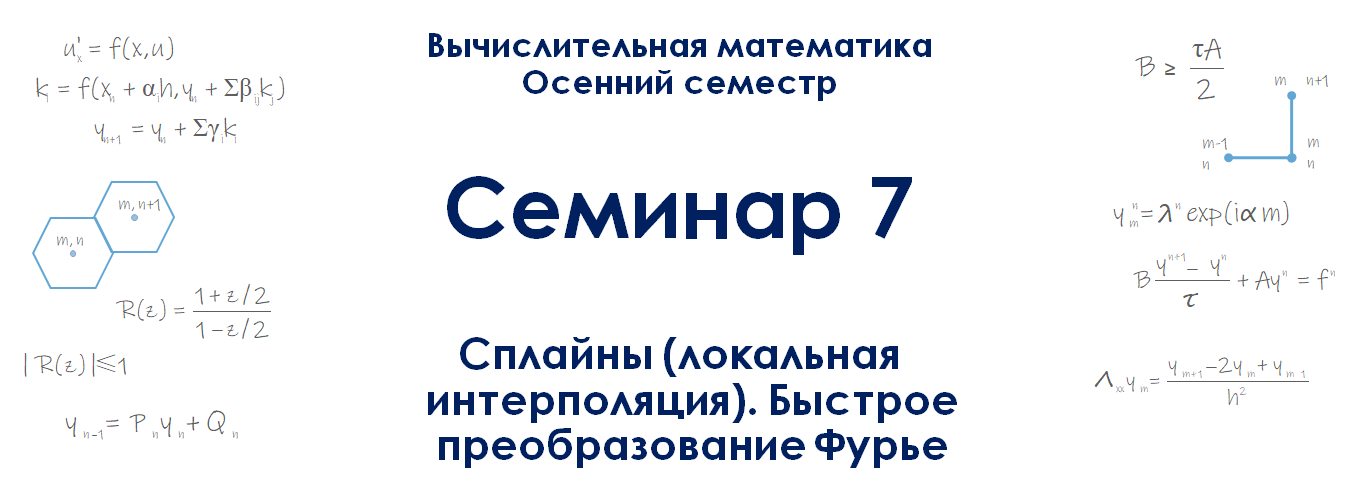

*Версия от 13.10.2026*

*Внимание! Семинар содержит интерактивные демонстрации. На сайте они представлены в статическом виде. Для работы интерактивных элементов необходимо скачать страницу в формате ipynb и запустить ipynb-файл локально.*

# Часть первая — Интерполяция сплайнами


*Перед изучением этой части семинара рекомендуем посетить лекцию или посмотреть видеозапись лекции. Ссылки (YouTube): [лекция 11](https://www.youtube.com/live/Kt2tcbBvudA?si=AzjMvzA-LbyRxWkN&t=101).*

Предполагается, что читатель знает

* определение разделённых разностей,
* асимптотическую сложность метода последовательных исключений Гаусса решения СЛАУ,
* смысл условия строгого диагонального преобладания для квадратной матрицы.


На предыдущем семинаре мы рассматривали **глобальную** интерполяцию функций алгебраическими полиномами. Мы выяснили, что если значения некоторой функции (функции-оригинала) известны в $n+1$ точках (узлах), то всегда можно построить единственный алгебраический полином степени не выше $n$, значения которого в рассматриваемых точках совпадают с заданными значениями функции. Мы научились строить интерполяционный полином в двух формах: Лагранжа и Ньютона, — а также получили ряд оценок на погрешность интерполяции. Оказалось, что минимизировать оценку погрешности можно путём специального выбора узлов сетки, на которой строится алгебраический интерполянт. Мы видели, что оптимальной является чебышёвская сетка: её использование гарантирует минимизацию погрешности метода (при прочих равных условиях) и сравнительно медленный — логарифмический — рост константы Лебега. Последнее означает, что при выборе чебышёвской сетки ошибки округления и погрешности входных данных (значений функции) оказывают меньшее влияние на результат интерполяции, чем при выборе, например, равномерной сетки с тем же числом узлов.

Из сказанного как будто бы следует, что глобальная алгебраическая интерполяция даёт удобный и вполне надёжный способ приближения функций с высокой точностью: можно получить "хорошее" приближение, если взять многочлен-интерполянт достаточно высокой степени и построить его на чебышёвской сетке. Однако не следует забывать о том, что

* выбором узлов сетки можно распоряжаться не всегда,
* с увеличением степени приближающего полинома $n$ ошибки округления накапливаются в любом случае (даже если используется чебышёвская сетка), так что при высокой степени $n$ эти ошибки могут оказаться значительными,
* выбор чебышёвской сетки усложняет вычисления,
* теоретическое обоснование равномерной сходимости интерполяционного процесса к функции-оригиналу при использовании специальных сеток опирается на предположение о достаточной гладкости функции-оригинала (а это предположение непроверяемо на практике и может оказаться неверным).

Наличие перечисленных недостатков сильно ограничивает область применения глобальной алгебраической интерполяции как метода **высокоточного** приближения функций и заставляет искать другие способы решения этой задачи. Одним из них является **локальная алгебраическая интерполяция**.

Суть локальной интерполяции очень проста: отрезок $[a,b]$, на котором необходимо построить интерполянт, разбивается на несколько более мелких подотрезков. На каждом из подотрезков функция интерполируется алгебраическим полиномом, причём обычно используются полиномы сравнительно невысоких степеней. Иначе говоря, **вместо одного полинома высокой степени используют кусочно-полиномиальное приближение**, т.е. каждый полином невысокой степени является интерполянтом функции **лишь на подотрезке**. Уточнение приближения достигается за счёт измельчения подотрезков, т.е. увеличения их **количества**, а не за счёт увеличения **степеней** полиномов. В результате удаётся избежать проблем, характерных для глобальной интерполяции алгебраическими полиномами высоких степеней.

Возникает, однако, другая особенность. При глобальной интерполяции функция-образ по построению является бесконечно гладкой во всех точках отрезка $[a,b]$ (поскольку эта функция представляет собой алгебраический полином). Если же используется локальная интерполяция, то отдельные "кусочки" функции-образа приходится как-то сшивать в граничных точках подотрезков, на которые разбивается исходный отрезок $[a,b]$. В связи с этим **гладкость получаемого приближения ограничивается гладкостью сшивки**.

Например, можно на каждом подотрезке приблизить функцию полиномом первой степени. Такому приближению можно дать наглядную геометрическую интерпретацию: на плоскости $(x,y)$ отмечаются точки, соответствующие известным значениям функции $y=f(x)$, после чего соседние точки соединяются отрезками. В результате получается ломаная линия (см. демонстрацию ниже). Это простейший пример **составного интерполянта**. Ясно, что чем мельче подотрезки, на которые разбивается отрезок $[a,b]$, тем точнее приближение функции составным интерполянтом.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

def create_table(n: int):
    fun = lambda x: np.cos(np.exp(2*x)) / (1 + x**2)
    f = np.vectorize(fun)
    x = np.linspace(-1, 1, n)
    y = f(x)

    return x, y

def polyline(n: int):
    fig, ax = plt.subplots()
    ax.plot(*create_table(1000), color='grey', alpha=0.3,
            label='Функция-оригинал $f(x)$', zorder=0)
    ax.scatter(*create_table(n+1), color='blue', s=8,
               label='Сеточная проекция $f_n$')
    ax.plot(*create_table(n+1), color='red',
            label='Составной интерполянт', zorder=0)


    ax.set_title("Кусочно-линейное приближение функции-оригинала")
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")

    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))

    plt.show()

In [2]:
from ipywidgets import interact, IntSlider

n_w = IntSlider(min=1, max=70, step=1, value=2)
interact(polyline, n=n_w);

interactive(children=(IntSlider(value=2, description='n', max=70, min=1), Output()), _dom_classes=('widget-int…

Однако у такого приближения есть недостаток: оно является лишь **кусочно**-гладким, т.е. в точках сшивки у функции-образа не существует даже первой производной (на графике интерполянта видны **изломы** в узлах сетки). Существенно, что с увеличением точности приближения (при измельчении сетки) количество таких изломов, очевидно, растёт. Следовательно, такой способ интерполяции неприменим, если требуется построить достаточно гладкую функцию-образ.

Для получения гладкой функции-образа необходимо увеличить степень полинома, используемого на каждом подотрезке, а также наложить на локальные алгебраические интерполянты специальные условия, гарантирующие непрерывность соответствующих производных в точках сшивки. Если снова обратиться к геометрической интерпретации, то можно сказать, что по заданным точкам **нужно строить не ломаную, а плавную кривую** (кривую без изломов). До появления и широкого распространения средств компьютерной графики подобные построения осуществлялись вручную с помощью специальных инструментов. Одним из них являлась гибкая металлическая или пластмассовая линейка, представлявшая собой нечто вроде "настраиваемого лекала" (см. рисунок ниже). Такую линейку можно было расположить на листе бумаги и зафиксировать так, чтобы она проходила через небольшое количество заданных точек, соединяя их плавной кривой. По-английски этот инструмент назывался "**spline**" (или "flat spline").

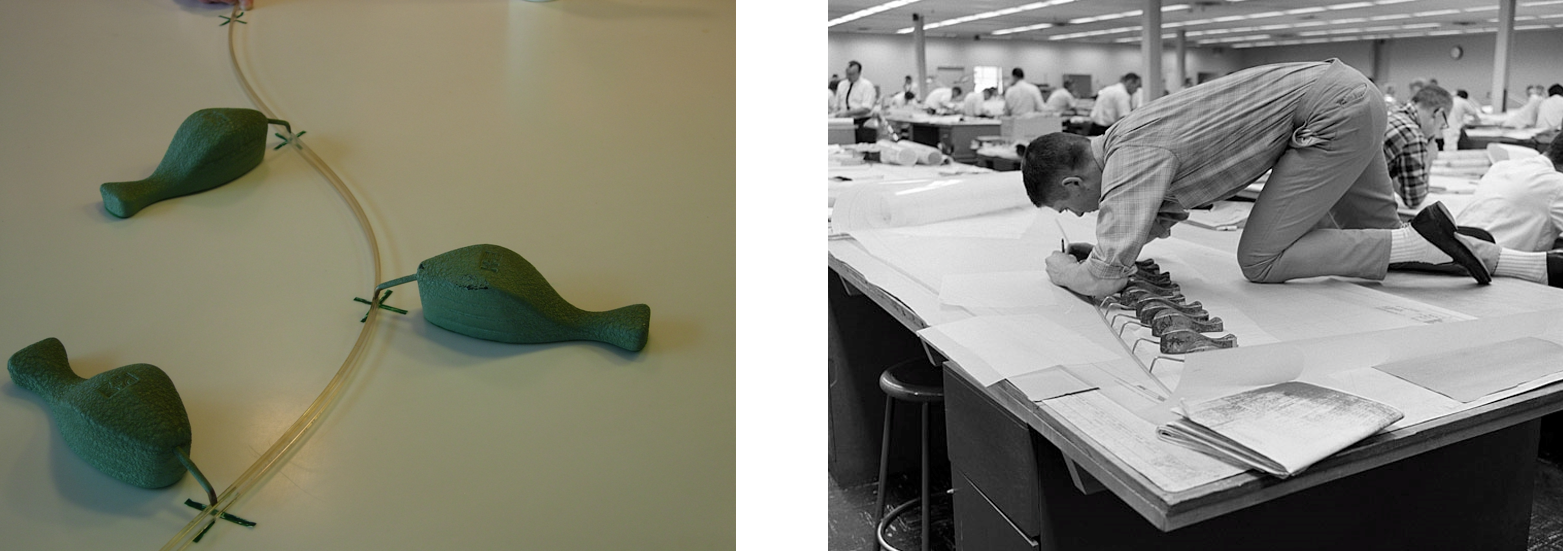

*На фото слева: гибкая линейка (flat spline) для соединения точек плавной кривой. На фото справа: чертёжник компании "Boeing", работающий с линейкой-сплайном.* [Ссылка](https://pages.cs.wisc.edu/~deboor/draftspline.html)

Изложенную процедуру приближения функции-оригинала плавной кривой легко формализовать: надо ввести в рассмотрение кусочно-полиномиальную функцию, имеющую несколько производных, непрерывных в точках сшивки алгебраических полиномов, а затем искать интерполянт среди функций этого класса. Подобные функции называются **сплайнами** (или сплайн-функциями); этот термин происходит от названия упомянутого выше чертёжного инструмента. Итак, приходим к определению.

**Определение 1.** Пусть на отрезке $[a,b]$ введена сетка $G_k$, состоящая из $k+1$ узлов $x_i$ таких, что $x_0=a$, $x_{k}=b$. *Сплайном (или сплайн-функцией) степени $n$ дефекта $\nu$* ($\nu$ — целое число такое, что $0\leq \nu\leq n+1$) называется функция $S_{n,\,\nu}=S_{n,\,\nu}(x)\in C^{n-\nu}[a,b]$, являющаяся многочленом степени $n$ на каждом отрезке $[x_{i-1},x_{i}]$:

$$S_{n,\,\nu}(x)\equiv P_n^{(i)}(x),\quad x\in[x_{i-1},x_{i}],\quad 1\leq i\leq k,$$

причём все $k$ многочленов $P_n^{(i)}(x)$, вообще говоря, могут быть различными. Узлы сетки $G_k$ будем называть *узлами сплайна*.

Иначе говоря, **сплайн — это функция фиксированной гладкости, сшитая из алгебраических полиномов, заданных на каждом из рассматриваемых подотрезков отрезка $[a,b]$** (степени всех полиномов обычно предполагаются одинаковыми, хотя это и не обязательно). Дефект сплайна показывает, сколько его старших производных "рвётся" на отрезке $[a,b]$; другими словами, по величине дефекта можно понять, насколько грубо сшиваются полиномы в узлах сплайна. Например, если дефект сплайна $\nu=1$, то это значит, что в узлах сплайна терпит разрыв только $n$-я производная функции $S_{n,\,\nu}$, а все производные меньших порядков непрерывны на всём отрезке $[a,b]$. Случаю наиболее грубой сшивки отвечает дефект $\nu=n$, при котором $S_{n,\,\nu}\in C^{0}[a,b]$, т.е. функция $S_{n,\,\nu}$ лишь непрерывна на отрезке $[a,b]$, но уже первая её производная "рвётся" по крайней мере в одном из узлов сплайна (пример такого сплайна приведён в демонстрации выше  — это кусочно-линейная функция, иными словами сплайн $S_{1,\,1}$). Если же $\nu=n+1$, то $S_{n,\,\nu}\in C^{-1}[a,b]$; это значит, что функция $S_{n,\,\nu}$ является лишь **кусочно**-непрерывной на отрезке $[a,b]$, т.е. имеет на этом отрезке не менее одного разрыва первого рода (разрывы расположены в узлах сплайна). В последнем случае сшивка полиномов вовсе отсутствует.

**Упражнение 1.** Что представляется собой сплайн $S_{n,\,0}$ с нулевым дефектом?

Вообще говоря, сплайны можно применять не только для приближения функций. Существуют, например, численные методы решения краевых дифференциальных задач, основанные на представлении искомых функций в виде сплайнов (так называемые методы **сплайн-коллокации**). В нашем курсе мы будем рассматривать только **интерполяционные сплайны**.

**Определение 2.** Пусть на отрезке $[a,b]$ введена сетка $G_m$ (состоящая из $m+1$ узлов $x_j$, $0\leq j\leq m$), а также определён сплайн $S_{n,\,\nu}=S_{n,\,\nu}(x)$, узлы которого, вообще говоря, *не совпадают* с узлами сетки $G_m$. Далее, пусть на сетке $G_m$ определена сеточная функция

$$
\mathscr F=\{(x_j,f_j)\}_{j=0}^{m} ,\qquad
f:G_m\to\mathbb R.
$$

Тогда сплайн $S_{n,\,\nu}$ называется *интерполяционным* для сеточной функции $\mathscr{F}$, если выполнено *условие интерполяционности*

$$S_{n,\,\nu}(x_j)=f(x_j)\equiv f_j,\quad 0\leq j\leq m.$$

Чаще всего в качестве интерполяционных рассматриваются сплайны с единичным дефектом: $\nu=1$, так что значение дефекта обычно не пишут и обозначают интерполяционный сплайн через $S_n\equiv S_{n,\,1}$.

Далее мы для простоты **будем считать, что узлы сплайна совпадают с узлами интерполяции**. Кроме того, ограничимся рассмотрением **кубических интерполяционных сплайнов**, получивших наиболее широкое распространение.

## Кубический интерполяционный сплайн

Согласно общему определению (см. определение 1), кубический сплайн $S_{3,\,\nu}$ строится как функция, которая на каждом подотрезке рассматриваемого отрезка $[a,b]$ представляет собой алгебраический полином третьей степени. Этот полином удобно записать в следующем виде:

$$P_3^{(i)}(x)\equiv S^{(i)}_{3,\,\nu}(x)=a_{i}+b_{i}(x-x_{i-1})+c_{i}(x-x_{i-1})^2+d_{i}(x-x_{i-1})^3,\quad x\in[x_{i-1},x_{i}],\quad 1\leq i\leq k.$$

Таким образом, "кусок" сплайна задаётся четырьмя коэффициентами $a_i$, $b_i$, $c_i$ и $d_i$, а весь сплайн $S_{3,\,\nu}$ однозначно определяется совокупностью из $4k$ коэффициентов.

Потребуем, чтобы сплайн $S_{3,\,\nu}$ был интерполяционным. Заметим, что

$$S^{(i)}_{3,\,\nu}(x_{i-1})=a_{i};\quad S^{(i)}_{3,\,\nu}(x_{i})=a_{i}+b_{i}h_{i}+c_{i}h_{i}^2+d_{i}h_{i}^3,\quad h_{i}\equiv x_{i}-x_{i-1}.$$

Поэтому условие интерполяционности (см. определение 2) переписывается в виде системы из $2k$ уравнений

$$a_{i}=f_{i-1},\quad a_{i}+b_{i}h_{i}+c_{i}h_{i}^2+d_{i}h_{i}^3=f_{i}, \quad 1\leq i\leq k.$$

Чтобы кубический сплайн $S_{3,\,\nu}$ имел единичный дефект ($\nu=1$), первые две ($n-\nu=3-1=2$) его производные должны быть непрерывны на отрезке $[a,b]$. Во внутренних точках всех подотрезков $[x_{i-1},x_{i}]$ непрерывность производных обеспечивается автоматически, поскольку в этих точках производные сплайна совпадают с производными полиномов третьей степени. Таким образом, достаточно обеспечить непрерывность производных в узлах сплайна. Для этого потребуем выполнения **условий гладкости сшивки**

$$\frac{dS^{(i)}_{3,\,\nu}}{dx}\Bigg|_{x_{i}-0}=\frac{dS^{(i+1)}_{3,\,\nu}}{dx}\Bigg|_{x_{i}+0},\qquad \frac{d^2S^{(i)}_{3,\,\nu}}{dx^2}\Bigg|_{x_{i}-0}=\frac{d^2S^{(i+1)}_{3,\,\nu}}{dx^2}\Bigg|_{x_{i}+0}$$

во **внутренних** узлах сплайна, т.е. при $1\leq i\leq k-1$. Находим производные:

$$\frac{dS^{(i)}_{3,\,\nu}}{dx}=b_{i}+2c_{i}(x-x_{i-1})+3d_{i}(x-x_{i-1})^2,$$

поэтому

$$\frac{dS^{(i)}_{3,\,\nu}}{dx}\Bigg|_{x_{i}-0}=b_{i}+2c_{i}h_{i}+3d_{i}h_{i}^2,\qquad\frac{dS^{(i+1)}_{3,\,\nu}}{dx}\Bigg|_{x_{i}+0}=b_{i+1};$$

далее

$$\frac{d^2S^{(i)}_{3,\,\nu}}{dx^2}=2c_{i}+6d_{i}(x-x_{i-1}),$$

следовательно,

$$\frac{d^2S^{(i)}_{3,\,\nu}}{dx^2}\Bigg|_{x_{i}-0}=2c_{i}+6d_{i}h_{i},\qquad \frac{d^2S^{(i+1)}_{3,\,\nu}}{dx^2}\Bigg|_{x_{i}+0}=2c_{i+1}.$$

Итак, условия гладкости сшивки дают ещё $2k-2$ уравнения:

$$b_{i}+2c_{i}h_{i}+3d_{i}h_{i}^2=b_{i+1},\quad c_{i}+3d_{i}h_{i}=c_{i+1},\quad 1\leq i\leq k-1.$$

Всего имеем $4k-2$ **линейных** уравнений на $4k$ коэффициентов сплайна ($2k$ уравнений из условия интерполяционности и $2k-2$ уравнений, выражающих условия гладкости сшивки). Для наглядности выпишем их все ещё раз:

$$\begin{cases}
    a_{i}=f_{i-1},\\[0.1cm]
    a_{i}+b_{i}h_{i}+c_{i}h_{i}^2+d_{i}h_{i}^3=f_{i},\\[0.1cm]
    b_{j}+2c_{j}h_{j}+3d_{j}h_{j}^2=b_{j+1},\\[0.1cm]
    c_{j}+3d_{j}h_{j}=c_{j+1}.
  \end{cases}$$

Мы сменили обозначение индекса во второй паре уравнений с целью подчеркнуть, что в двух последних уравнениях индекс пробегает меньше значений, чем в двух первых: $1\leq i\leq k$, а $1\leq j\leq k-1$. Из выписанной системы можно исключить коэффициенты $a_i$, $d_i$ и $b_i$. Коэффициент $a_i$ исключается тривиально. Для исключения $d_j$ выразим его из четвёртого уравнения:

$$d_j=\frac{c_{j+1}-c_j}{3h_j}.$$

Это выражение можно сразу подставить в третье уравнение (поскольку в нём фигурирует именно величина $d_j$). Подстановка же во второе уравнение наталкивается на затруднение: уравнение должно удовлетворяться в том числе при $i=k$, а последняя формула выражает $d_j$ через $c_j$ и $c_{j+1}$ лишь при $1\leq j\leq k-1$. Чтобы обойти это затруднение, введём в рассмотрение дополнительные неизвестные $a_{k+1}$, $b_{k+1}$, $c_{k+1}$ и $d_{k+1}$ (из них нам в дальнейшем понадобится только $c_{k+1}$), а также **фиктивный подотрезок** $[x_{k},\xi]=[b,\xi]$, где $\xi>b$. Доопределим сплайн на этом подотрезке "куском" $S_{3,\,\nu}^{(k+1)}$. Из формул, установленных выше при дифференцировании, следует, что

$$c_{k+1}=\frac{1}{2}\frac{d^2S^{(k+1)}_{3,\,\nu}}{dx^2}\Bigg|_{x_{k}+0}.$$

Требование гладкости сшивки с дополнительным "куском" $S_{3,\,\nu}^{(k+1)}$ позволяет продолжить равенство:

$$c_{k+1}=\frac{1}{2}\frac{d^2S^{(k+1)}_{3,\,\nu}}{dx^2}\Bigg|_{x_{k}+0}=\frac{1}{2}\frac{d^2S^{(k)}_{3,\,\nu}}{dx^2}\Bigg|_{x_{k}-0}\equiv \frac{1}{2}\frac{d^2S_{3,\,\nu}}{dx^2}\Bigg|_{x_{k}-0}.$$

Ясно, что это верно при сколь угодно малом $\xi$. Поэтому фиктивный отрезок (вместе со вспомогательным "куском" $S_{3,\,\nu}^{(k+1)}$) можно отбросить и считать, что коэффициент $c_{k+1}$ определяется значением (односторонней) производной сплайна $S_{3,\,\nu}$ в его правом граничном узле. Аналогичный смысл имеет коэффициент $c_1$ (это следует непосредственно из выписанных выше формул для второй производной):

$$c_{1}=\frac{1}{2}\frac{d^2S^{(1)}_{3,\,\nu}}{dx^2}\Bigg|_{x_{0}+0}\equiv \frac{1}{2}\frac{d^2S_{3,\,\nu}}{dx^2}\Bigg|_{x_{0}+0}.$$

Подчеркнём, что коэффициенты $c_1$ и $c_{k+1}$ не входят ни в условия интерполяционности, ни в условия гладкости сшивки и при необходимости должны определяться из каких-то дополнительных соображений.

Итак, выражение для $d_j$ может быть распространено и на коэффициент $d_k$ (поскольку выяснен смысл коэффициента $c_{k+1}$). Таким образом,

$$d_i=\frac{c_{i+1}-c_i}{3h_i},\quad 1\leq i\leq k.$$

После исключения величин $a_i$ и $d_i$ система условий на коэффициенты принимает вид:

$$\begin{cases}
    \displaystyle b_i=\frac{f_i-f_{i-1}}{h_i}-\frac{2c_i+c_{i+1}}{3}\,h_i,\\[0.1cm]
    \displaystyle c_{j+1}+c_j=\frac{b_{j+1}-b_{j}}{h_j}.
  \end{cases}$$

Подставляя первое уравнение во второе и выполняя простые алгебраические преобразования, получаем:

$$c_jh_j+2c_{j+1}(h_j+h_{j+1})+c_{j+2}h_{j+1}=3\bigg(\frac{f_{j+1}-f_j}{h_{j+1}}-\frac{f_j-f_{j-1}}{h_j}\bigg),\quad 1\leq j\leq k-1.$$

Удобно сместить индекс на единицу и заметить, что правая часть может быть выражена через разделённую разность второго порядка:

$$c_{j-1}h_{j-1}+2c_{j}(h_{j-1}+h_{j})+c_{j+1}h_{j}=3(h_{j-1}+h_{j})\cdot f(x_{j-2},x_{j-1},x_{j}),\quad 2\leq j\leq k.$$

Выписанные условия образуют СЛАУ из $k-1$ уравнений на $k+1$ коэффициентов $c_i$ ($1\leq i\leq k+1$). В матричном виде эта **недоопределённая** СЛАУ может быть записана так:

$$\textbf{S}\textbf{c}=\textbf{f}.$$

Матрица $\textbf{S}$ размера $(k-1)\times(k+1)$ **близка к трёхдиагональной**:

$$\textbf{S}=\begin{pmatrix}
    h_1 & 2(h_1+h_2) & h_2 & \dots & 0 & 0 & 0 \\
    0   & h_2 & 2(h_2+h_3) & \ddots & \vdots & \vdots & \vdots \\
    0   & 0   & h_3 & \ddots & h_{k-2} & 0 & 0 \\
    \vdots & \vdots & \vdots & \ddots & 2(h_{k-2}+h_{k-1}) & h_{k-1} & 0 \\
    0 & 0 & 0 & \dots & h_{k-1} & 2(h_{k-1}+h_k) & h_k
  \end{pmatrix},$$

Векторы неизвестных и правых частей задаются очевидным образом:

$$\textbf{c}=
  \begin{pmatrix}
    c_1 \\
    c_2 \\
    \vdots \\
    c_{k+1}
  \end{pmatrix},\quad
  \textbf{f}=3
  \begin{pmatrix}
    (h_1+h_2)\cdot f(x_0,x_1,x_2) \\
    (h_2+h_3)\cdot f(x_1,x_2,x_3) \\
    \vdots \\
    (h_{k-1}+h_{k})\cdot f(x_{k-2},x_{k-1},x_k)
  \end{pmatrix}.$$



Чтобы сделать возможным решение СЛАУ $\textbf{S}\textbf{c}=\textbf{f}$, надо доопределить (замкнуть) её путём добавления двух недостающих условий на $k+1$ величин $c_i$. Эти условия можно выбирать по-разному; при этом будут получаться различные типы сплайнов. Как правило, выбор недостающих условий так или иначе связан с поведением сплайна на границах рассматриваемого отрезка $[a,b]$. Поэтому говорят, что на сплайн требуется наложить некоторые **граничные условия**. Для этого достаточно из каких-либо соображений зафиксировать (явно или неявно) значения упоминавшихся выше коэффициентов $c_1$ и $c_{k+1}$. Перечислим некоторые из возможных вариантов.

* **Естественный (или свободный) сплайн.** Для его получения полагают

  $$c_1=c_{k+1}=0.$$

  Выше мы установили смысл коэффициентов $c_1$ и $c_{k+1}$: они равны (с точностью до множителя $1/2$) односторонним вторым производным сплайна в его граничных узлах. Поэтому наложенные условия означают, что

  $$\frac{d^2S_{3,\,\nu}}{dx^2}\Bigg|_{x_{0}+0}=\frac{d^2S_{3,\,\nu}}{dx^2}\Bigg|_{x_{k}-0}=0.$$

  Естественным (или свободным) такой сплайн называется в силу своего физического смысла: можно показать, что он удовлетворяет линеаризованному дифференциальному уравнению Бернулли—Эйлера, описывающему изгиб упругой многоопорной балки при отсутствии внешних нагрузок. Другими словами, если взять гибкую металлическую линейку, поставить её на ребро и закрепить в некотором количестве точек (без внешней нагрузки), то она изогнётся так, что будет иметь **нулевую кривизну** (нулевую вторую производную) в граничных точках.

* **Фундаментальный сплайн.** Получается по аналогии с естественным, только на границах зануляются не вторые производные, а первые. Для построения такого сплайна СЛАУ на коэффициенты удобнее записывать в терминах коэффициентов $b_i$. В наших обозначениях условия выглядят так:

  $$2c_1+c_2=\frac{3(f_1-f_0)}{h_1^2},\quad 2c_{k+1}+c_k=\frac{3(f_{k-1}-f_k)}{h_k^2}.$$

* **Сплайн с "отсутствующими узлами" (или эмпирический сплайн, или сплайн "not-a-knot").** Получается из требования непрерывности **третьей** производной в **приграничных** узлах ($i=1$ и $i=k-1$):

  $$\frac{d^3S_{3,\,\nu}^{(1)}}{dx^3}\Bigg|_{x_{1}-0}=\frac{d^3S_{3,\,\nu}^{(2)}}{dx^3}\Bigg|_{x_{1}+0},\quad \frac{d^3S_{3,\,\nu}^{(k-1)}}{dx^3}\Bigg|_{x_{k-1}-0}=\frac{d^3S_{3,\,\nu}^{(k)}}{dx^3}\Bigg|_{x_{k-1}+0}.$$

  Поскольку мы рассматриваем кубические сплайны, эти условия эквивалентны тождественности "кусков" сплайна $S_{3,\,\nu}^{(1)}$ и $S_{3,\,\nu}^{(2)}$, а также $S_{3,\,\nu}^{(k-1)}$ и $S_{3,\,\nu}^{(k)}$. Иначе говоря, пары отрезков $[x_0,x_1]$ и $[x_1,x_2]$, а также $[x_{k-2},x_{k-1}]$ и $[x_{k-1},x_{k}]$ объединяются в "двойные" отрезки $[x_0,x_2]$ и $[x_{k-2},x_{k}]$ соответственно, причём на каждом из них функция-оригинал приближается одним кубическим многочленом (своим в случае каждого "двойного" отрезка). Получается, что приграничные узлы $x_1$ и $x_{k-1}$ как бы "выключаются": они не разграничивают подотрезки, на которых функция приближается разными многочленами. Соответствующие условия на коэффициенты:

  $$\frac{c_2-c_1}{h_1}-\frac{c_3-c_2}{h_2}=0,\quad \frac{c_{k+1}-c_k}{h_k}-\frac{c_k-c_{k-1}}{h_{k-1}}=0.$$

* **Периодический сплайн.** Используется для приближений периодических функций, период которых укладывается на отрезке $[a,b]$ целое число раз. Из трёх условий периодичности

  $$S_{3,\,\nu}(x_0)=S_{3,\,\nu}(x_k),\quad \frac{dS_{3,\,\nu}}{dx}\Bigg|_{x_{0}+0}=\frac{dS_{3,\,\nu}}{dx}\Bigg|_{x_{k}-0},\quad \frac{d^2S_{3,\,\nu}}{dx^2}\Bigg|_{x_{0}+0}=\frac{d^2S_{3,\,\nu}}{dx^2}\Bigg|_{x_{k}-0}$$

  первое удовлетворяется автоматически в силу условия интерполяционности. Два других приводят к равенствам

  $$(2c_1+c_2)h_1+(c_k+2c_{k+1})h_k=3\bigg[\frac{f_1-f_0}{h_1}-\frac{f_k-f_{k-1}}{h_k}\bigg],\quad c_1-c_{k+1}=0.$$

Мы ограничимся рассмотрением только естественных сплайнов. Подчеркнём, что этот тип сплайнов **не является наилучшим среди перечисленных**. Его разумно использовать лишь в тех случаях, когда про функцию-оригинал известно, что $f''(a)=f''(b)=0$. То же самое можно утверждать и про фундаментальный сплайн: его применение оправданно, если $f'(a)=f'(b)=0$. В остальных случаях искусственное зануление производных сплайна на границах отрезка (иногда рекомендуемое в литературе) будет приводить к значительному увеличению погрешности приближения вблизи граничных узлов. Поэтому если про граничные условия на функцию-оригинал ничего не известно, то предпочтительнее пользоваться эмпирическим сплайном — как правило, он даёт наилучшие результаты (по этой причине именно эта разновидность сплайнов реализована в большинстве программных пакетов).

После добавления к СЛАУ $\textbf{S}\textbf{c}=\textbf{f}$ условий $c_1=c_{k+1}=0$ она принимает следующий вид:

$$\begin{pmatrix}
    1 & 0 & \dots & 0 & 0 \\ \hline
    & & \textbf{S} \\ \hline
    0 & 0 & \dots & 0 & 1
  \end{pmatrix}
  \begin{pmatrix}
    c_1 \\
    \vdots \\
    c_{k+1}
  \end{pmatrix}=
  \begin{pmatrix}
    0 \\ \hline
    \textbf{f} \\ \hline
    0
  \end{pmatrix}.$$

Легко видеть, что эта СЛАУ эквивалентна СЛАУ $\widetilde{\textbf{S}}\widetilde{\textbf{c}}=\widetilde{\textbf{f}}$ с "обрезанным" столбцом неизвестных

$$\widetilde{\textbf{c}}=
  \begin{pmatrix}
    c_2 \\
    c_3 \\
    \vdots \\
    c_{k}
  \end{pmatrix},$$

прежним столбцом правых частей ($\widetilde{\textbf{f}}=\textbf{f}$) и матрицей

$$\widetilde{\textbf{S}}=\begin{pmatrix}
    2(h_1+h_2) & h_2 & 0 & \dots & 0 & 0 & 0\\
    h_2 & 2(h_2+h_3) & h_3 & \dots & 0 & 0 & 0\\
    0   &  h_3 & 2(h_3+h_4)& \dots & 0 & 0 & 0 \\
    \vdots & \vdots & \vdots & \ddots & \vdots & \vdots & \vdots \\
    0 & 0 & 0 & \dots & 2(h_{k-3}+h_{k-2}) & h_{k-2} & 0 \\
    0 & 0 & 0 & \dots & h_{k-2}& 2(h_{k-2}+h_{k-1}) & h_{k-1} \\
    0 & 0 & 0 & \dots & 0 & h_{k-1} & 2(h_{k-1}+h_k)
  \end{pmatrix}.$$

Это квадратная **трёхдиагональная** матрица порядка $k-1$, полученная из матрицы $\textbf{S}$ отсечением крайнего левого и крайнего правого столбцов.

Если сетка, на которой строится сплайн, является равномерной, то последняя СЛАУ значительно упрощается:

$$\widetilde{\textbf{S}}=\begin{pmatrix}
    4 & 1 & 0 & \dots & 0 & 0 & 0\\
    1 & 4 & 1 & \dots & 0 & 0 & 0\\
    0 & 1 & 4 & \dots & 0 & 0 & 0 \\
    \vdots & \vdots & \vdots & \ddots & \vdots & \vdots & \vdots \\
    0 & 0 & 0 & \dots & 4 & 1 & 0 \\
    0 & 0 & 0 & \dots & 1 & 4 & 1 \\
    0 & 0 & 0 & \dots & 0 & 1 & 4
  \end{pmatrix},\quad\widetilde{\textbf{c}}=
  \begin{pmatrix}
    c_2 \\
    c_3 \\
    \vdots \\
    c_{k}
  \end{pmatrix},\quad
  \widetilde{\textbf{f}}=6
  \begin{pmatrix}
    f(x_0,x_1,x_2) \\
    f(x_1,x_2,x_3) \\
    \vdots \\
    f(x_{k-2},x_{k-1},x_k)
  \end{pmatrix}.$$

Заметим, что от значений функции-оригинала здесь зависит только столбец правых частей.

Итак, для построения **естественного** кубического интерполяционного сплайна $S_3$ по заданной таблице из $k+1$ значений некоторой функции $f=f(x)$ необходимо

* найти разделённые разности второго порядка $f(x_i,\,x_{i+1},\,x_{i+2})$ (в количестве $k-1$),
* составить СЛАУ $\widetilde{\textbf{S}}\widetilde{\textbf{c}}=\widetilde{\textbf{f}}$ на $k-1$ коэффициентов $c_i$ ($2\leq i\leq k$), пользуясь формулами для матрицы $\widetilde{\textbf{S}}$ и столбца $\widetilde{\textbf{f}}$, выписанными выше,
* решить получившуюся СЛАУ и учесть, что $c_1=c_{k+1}=0$,
* найти остальные коэффициенты $a_i$, $b_i$, $d_i$ по формулам

  $$a_i=f_{i-1},\quad b_i=\frac{f_i-f_{i-1}}{h_i}-\frac{2c_i+c_{i+1}}{3}\,h_i,\quad d_i=\frac{c_{i+1}-c_i}{3h_i};\quad h_i=x_i-x_{i-1},\quad 1\leq i\leq k,$$

* записать $k$ "кусков" сплайна:

  $$S^{(i)}_{3}(x_{i-1}\leq x\leq x_i)=a_{i}+b_{i}(x-x_{i-1})+c_{i}(x-x_{i-1})^2+d_{i}(x-x_{i-1})^3,\quad 1\leq i\leq k.$$

В учебных задачах мы будем рассматривать случаи небольших $k$, когда СЛАУ на коэффициенты $c_i$ легко решается вручную. Однако на практике при использовании сплайн-интерполяции рассматриваются случаи больших $k$ (порядка $10^2$ и даже $10^3$). Разумеется, в таких случаях соответствующая СЛАУ должна решаться численно и возникает вопрос о выборе эффективного алгоритма для её решения.

Наиболее эффективным методом решения СЛАУ с трёхдиагональной матрицей является **метод скалярной трёхточечной прогонки**. Изложим коротко суть этого метода.

## Метод прогонки решения СЛАУ с трёхдиагональной матрицей

Метод скалярной трёхточечной прогонки (далее мы для краткости будем называть его просто **методом прогонки**; в англоязычной литературе он часто называется **алгоритмом Томаса**) представляет собой модификацию метода последовательных исключений Гаусса, использующуюся для решения СЛАУ с **трёхдиагональной** матрицей. Расчётные формулы метода прогонки можно вывести, выполнив по обычным правилам прямой и обратный ходы метода Гаусса **с учётом трёхдиагональной структуры матрицы**. Мы выведем те же формулы иначе.

Пусть требуется решить СЛАУ $\textbf{A}\textbf{x}=\textbf{f}$ с трёхдиагональной матрицей $\textbf{A}$ порядка $n$:

$$\textbf{A}=\begin{pmatrix}
    \beta_1 & \gamma_1 & 0 & 0 & \dots & 0\\
    \alpha_2 & \beta_2 & \gamma_2 & 0 & \dots & 0\\
    0 & \alpha_3 & \beta_3 & \gamma_3 & \dots & 0\\
    0 & 0 & \ddots & \ddots & \ddots & 0\\
    0 & 0 & \dots & \alpha_{n-1} & \beta_{n-1} & \gamma_{n-1} \\
    0 & 0 & \dots & 0 & \alpha_{n} & \beta_{n}
  \end{pmatrix}.$$

Заметим, что матрица $\textbf{A}$ однозначно задаётся тремя массивами коэффициентов: $\alpha_i$, $\beta_i$ и $\gamma_i$, — причём массив $\beta_i$ имеет длину $n$, а массивы $\alpha_i$ и $\gamma_i$ — длину $n-1$.

Запишем СЛАУ в покомпонентной форме:

$$\begin{align}
    \beta_1\cdot x_1 + \gamma_1\cdot x_2 &= f_1,\\
    \alpha_i\cdot x_{i-1}+\beta_i\cdot x_i+\gamma_i\cdot x_{i+1}&=f_i,\quad 2\leq i\leq n-1,\\
    \alpha_n x_{n-1} +\beta_n x_n&=f_n.
  \end{align}$$

Будем искать её решение в виде

$$x_i=p_i\cdot x_{i+1}+q_i,\quad 1\leq i\leq n-1.$$

Эта формула называется **прогоночным соотношением**, а коэффициенты $p_i$ и $q_i$ называются **прогоночными коэффициентами**.

С помощью прогоночного соотношения исключим из уравнений СЛАУ величины $x_{i-1}$ при $2\leq i\leq n-1$; кроме того, из первого уравнения ($i=1$) выразим $x_1$:

$$\begin{align}
    x_1&=-\frac{\gamma_1}{\beta_1}x_2+\frac{f_1}{\beta_1},\\[0.2cm]
    x_i&=-\frac{\gamma_i}{\beta_i+\alpha_ip_{i-1}}\cdot x_{i+1}+\frac{f_i-\alpha_iq_{i-1}}{\beta_i+\alpha_ip_{i-1}},\quad 2\leq i\leq n-1.
  \end{align}$$

Сравнивая эти формулы с прогоночным соотношением, легко устанавливаем, что

$$\begin{align}
    p_1&=-\frac{\gamma_1}{\beta_1},\quad q_1=\frac{f_1}{\beta_1};\\[0.2cm]
    p_i&=-\frac{\gamma_i}{\beta_i+\alpha_ip_{i-1}},\quad q_i=\frac{f_i-\alpha_i q_{i-1}}{\beta_i+\alpha_ip_{i-1}},\quad 2\leq i\leq n-1.
  \end{align}$$

Заметим, что случай $i=1$ можно охватить общими формулами для $2\leq i\leq n-1$, если положить $\alpha_1=0$ (значения $p_0$ и $q_0$ при необходимости — например, в ходе программной реализации — можно доопределить любым способом). Окончательно имеем следующие рекуррентные соотношения:

$$p_i=-\frac{\gamma_i}{\beta_i+\alpha_ip_{i-1}},\quad q_i=\frac{f_i-\alpha_i q_{i-1}}{\beta_i+\alpha_ip_{i-1}},\quad 1\leq i\leq n-1,\quad \alpha_1=0.$$

С помощью этих формул можно вычислить все прогоночные коэффициенты (в количестве $2n-2$). После этого остаётся найти последнюю компоненту решения $x_n$ — прочие компоненты определятся автоматически посредством рекуррентной связи, заданной прогоночным соотношением.

Величина $x_{n}$ входит в два равенства (последнее уравнение СЛАУ и прогоночное соотношение при $i=n-1$):

$$\alpha_n x_{n-1} +\beta_n x_n=f_n,\quad x_{n-1}=p_{n-1}\cdot x_n+q_{n-1}.$$

Исключая отсюда $x_{n-1}$, находим:

$$x_n=\frac{f_n-\alpha_nq_{n-1}}{\beta_n+\alpha_np_{n-1}}\equiv q_n.$$

Итак, имеем следующий алгоритм решения СЛАУ с трёхдиагональной матрицей, заданной массивами $\alpha_i$, $\beta_i$ и $\gamma_i$:

* дополнить массив $\alpha_i$ (имеющий длину $n-1$) значением $\alpha_1=0$,
* создать два массива прогоночных коэффициентов: $p_i$ (длины $n$ — с учётом произвольного значения $p_0$) и $q_j$ (длины $n+1$ — с учётом произвольного значения $q_0$) — и вычислить их элементы по следующим рекуррентным формулам (**этап прямой прогонки**):

  $$p_i=-\frac{\gamma_i}{\beta_i+\alpha_ip_{i-1}},\quad 1\leq i\leq n-1;\qquad q_j=\frac{f_j-\alpha_j q_{j-1}}{\beta_j+\alpha_jp_{j-1}},\quad 1\leq j\leq n,$$

* положить $x_n=q_n$,
* вычислить все остальные компоненты решения с помощью прогоночного соотношения (**этап обратной прогонки**):

  $$x_i=p_i\cdot x_{i+1}+q_i,\quad i=n-1,\,n-2,\,\dots,\,1.$$

Легко подсчитать, что для решения СЛАУ с трёхдиагональной матрицей порядка $n$ методом прогонки необходимо выполнить $8n-3$ арифметических действий (мы учли, что рекуррентные формулы для прогоночных коэффициентов имеют одинаковые знаменатели). Таким образом, **метод прогонки имеет линейную вычислительную сложность**. Это выгодно отличает его от метода Гаусса для матриц общего вида (напомним, что последний имеет сложность $O(n^3)$ — см. семинар 2).

При построении метода прогонки мы молчаливо предполагали, что все величины $\beta_j+\alpha_jp_{j-1}$ (в количестве $n$) отличны от нуля, так что при расчёте прогоночных коэффициентов не возникает деления на нуль. Вообще говоря, в случае произвольной трёхдиагональной матрицы СЛАУ какая-то из величин $\beta_j+\alpha_jp_{j-1}$ может и занулиться. Оказывается, однако, что если трёхдиагональная матрица СЛАУ удовлетворяет условию (нестрогого) диагонального преобладания, т.е.

$$|\beta_i| \geq |\alpha_i|+|\gamma_i|,\quad 1\leq i\leq n\quad (\alpha_1=\gamma_n=0),$$

и **хотя бы в одной строке** выполнено условие **строгого** диагонального преобладания, то на этапе прямой прогонки деления на нуль не встретится. Более того, выполнение этих условий гарантирует устойчивость метода (при вычислении произведений, входящих в рекуррентные формулы, не будут накапливаться ошибки округления). Поэтому на практике **использовать метод прогонки следует только для трёхдиагональных матриц с диагональным преобладанием**.

Программную реализацию метода прогонки мы предоставляем читателю (см. практическую задачу A).

**Упражнение 2.** Получить расчётные формулы метода скалярной **пятиточечной** прогонки для решения СЛАУ с **пятидиагональной** матрицей (ненулевые элементы расположены только на главной диагонали, двух диагоналях под главной и двух диагоналях над главной).

В предыдущем разделе при построении естественного кубического сплайна на равномерной сетке мы получили СЛАУ с трёхдиагональной матрицей, у которой $\alpha_i=\gamma_i=1$ и $\beta_i=4$ (для всех доступных $i$). Условие строгого диагонального преобладания, очевидно, выполнено, поэтому метод прогонки в данном случае корректен и устойчив. Формулы для прогоночных коэффициентов упрощаются:

$$p_1=-\frac{1}{4},\quad p_i=-\frac{1}{4+p_{i-1}},\quad 2\leq i\leq n-1;\qquad q_1=\frac{f_1}{4},\quad q_j=\frac{f_j-q_{j-1}}{4+p_{j-1}},\quad 2\leq j\leq n.$$

## О сходимости сплайн-интерполяции

Выше мы подробно разобрали процедуру построения естественного кубического интерполяционного сплайна. Возникает вопрос: в каких случаях использование сплайн-интерполяции корректно, т.е. при каких условиях последовательность интерполяционных сплайнов будет равномерно сходиться к функции-оригиналу $f$?

Оказывается, что равномерная сходимость процесса сплайн-интерполяции имеет место при достаточно общих предположениях относительно функции-оригинала. Конкретные оценки зависят от выбранной сетки и типа сплайна. Например, для равномерной сходимости последовательности периодических сплайнов, построенных на равномерных сетках, достаточно одной только непрерывности функции-оригинала.

Мы приведём без доказательства оценки погрешностей сплайн-интерполяции для случая **естественного** кубического сплайна, построенного на **равномерной** сетке.

**Теорема 1.** Пусть на отрезке $[a,b]$ определена функция-оригинал $f=f(x)$, причём $f\in C^4[a,b]$, $f''(a)=f''(b)=0$. Пусть далее $S_3=S_3(x)$ — *естественный* кубический интерполяционный сплайн (единичного дефекта), построенный по значениям функции $f$ в узлах *равномерной* сетки с шагом $h$. Тогда справедливы оценки

$$\Vert f(x)-S_3(x)\Vert_C\leq M_4h^4,\quad \Vert f'(x)-S_3'(x)\Vert_C\leq M_4h^3,\quad \Vert f''(x)-S_3''(x)\Vert_C\leq M_4h^2.$$

Здесь, как всегда, $M_4=\sup\limits_{x\in[a,b]}\big|f^{(4)}(x)\big|$.

## Задача 1

Построить **естественный** кубический интерполяционный сплайн по нижеследующей таблице значений функции $f(x)=\cos(\pi x/6)$. Найти с его помощью приближённое значение функции в точке $x=3/2$ и сравнить его с точным значением.

$$
\begin{array}{c|ccccc}
  x_i & 0 & 1 & 2 & 3 & 4 \\
  \hline
  f_i & 1,000 & 0,866 & 0,500 & 0,000 & -0,500
\end{array}
$$

**Решение.** Предложенная в условии сетка является равномерной с шагом $h=1$ и содержит $k+1=5$ узлов. Поэтому СЛАУ для определения коэффициентов естественного сплайна принимает следующий вид:

$$\begin{pmatrix}
    4 & 1 & 0 \\
    1 & 4 & 1 \\
    0 & 1 & 4
  \end{pmatrix}
  \begin{pmatrix}
    c_2 \\
    c_3 \\
    c_4
  \end{pmatrix}=
  6\begin{pmatrix}
    f(x_0,x_1,x_2) \\
    f(x_1,x_2,x_3) \\
    f(x_2,x_3,x_4)
  \end{pmatrix}.
  $$

Построим таблицу разделённых разностей для вычисления правой части:

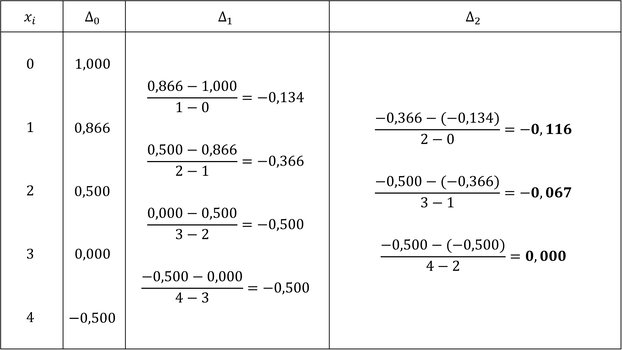

*Фрагмент таблицы разделённых разностей к решению задачи 1*

Таким образом, получаем СЛАУ:

$$\begin{pmatrix}
    4 & 1 & 0 \\
    1 & 4 & 1 \\
    0 & 1 & 4
  \end{pmatrix}
  \begin{pmatrix}
    c_2 \\
    c_3 \\
    c_4
  \end{pmatrix}=
  \begin{pmatrix}
    -0,696 \\
    -0,402 \\
    0,000
  \end{pmatrix}.
  $$

Её решение:

$$c_2=-0,158,\quad c_3=-0,065,\quad c_4=0,016.$$

Коэффициенты $c_1$ и $c_5$ равны нулю по построению естественного сплайна: $c_1=c_5=0$. Итак, все коэффициенты $c_i$ найдены.

Коэффициенты $b_i$ и $d_i$ вычисляем по формулам ($h=1$):

$$b_i=f_i-f_{i-1}-\frac{2c_i+c_{i+1}}{3},\quad d_i=\frac{c_{i+1}-c_i}{3},\quad 1\leq i\leq k=4.$$

Получаем:

$$b_1=-0,081,\quad b_2=-0,239,\quad b_3=-0,462,\quad b_4=-0,511;$$

$$d_1= -0,053,\quad d_2= 0,031,\quad d_3= 0,027,\quad d_4= -0,005.$$

Наконец, коэффициенты $a_i$ совпадают с табличными значениями функции:

$$a_i=f_{i-1},\quad 1\leq i\leq k;\quad a_1=1,000,\quad a_2=0,866,\quad a_3=0,500,\quad a_4=0,000.$$

Остаётся "собрать" все четыре "куска" сплайна:

$$\begin{align}
  S_3^{(1)}(0\leq x\leq 1)&= 1,000-0,081x-0,053x^3;\\[0.2cm]
  S_3^{(2)}(1\leq x\leq 2)&= 0,866-0,239(x-1)-0,158(x-1)^2+0,031(x-1)^3;\\[0.2cm]
  S_3^{(3)}(2\leq x\leq 3)&= 0,500-0,462(x-2)-0,065(x-2)^2+0,027(x-2)^3;\\[0.2cm]
  S_3^{(4)}(3\leq x\leq 4)&=-0,511(x-3)+0,016(x-3)^2-0,005(x-3)^3.
  \end{align}$$

В точке $x=3/2$ сплайн принимает значение

$$S_3\bigg(\frac{3}{2}\bigg)=S_3^{(2)}\bigg(\frac{3}{2}\bigg)= 0,711,$$

а функция-оригинал $f$ — значение:

$$f\bigg(\frac{3}{2}\bigg)=\cos\frac{\pi}{4}=\frac{\sqrt{2}}{2}\simeq 0,707.$$

Абсолютная погрешность приближённого значения есть

$$\delta=\Bigg|S_3^{(2)}\bigg(\frac{3}{2}\bigg)-f\bigg(\frac{3}{2}\bigg)\Bigg|\simeq 4\cdot 10^{-3},$$

что соответствует относительной погрешности $\varepsilon = 0,6\%$.





Проверим результаты решения задачи с помощью готовой реализации сплайнов, имеющейся в модуле ```interpolate``` библиотеки ```scipy``` ([документация](https://docs.scipy.org/doc/scipy/reference/interpolate.html)). Этот модуль содержит класс ```CubicSpline``` ([документация](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.html)), поддерживающий создание кубических интерполяционных сплайнов и простейшие операции с ними.

Для построения сплайна (расчёта его коэффициентов) достаточно передать конструктору класса массивы $x_i$ и $f_i$ (равной длины), составляющие таблицу значений неизвестной функции-оригинала. По умолчанию будет создан эмпирический сплайн (сплайн с "отсутствующими узлами"). Чтобы построить сплайн другого типа, надо присвоить необязательному аргументу ```bc_type``` конструктора значение в виде соответствующей строки-ключа. Класс ```CubicSpline``` поддерживает четыре основных типа сплайнов. Перечислим их с указанием строк-ключей:

* ```natural``` — естественный (свободный) сплайн,
* ```clamped``` — фундаментальный сплайн,
* ```not-a-knot``` (выбран по умолчанию) — эмпирический сплайн,
* ```periodic``` — периодический сплайн.

Отметим, что можно задать различные условия на левой ($x=a$) и правой ($x=b$) границах. Для этого в качестве аргумента ```bc_type``` следует передать кортеж длины 2 из двух строк-ключей: первая задаст граничное условие слева, вторая — граничное условие справа. В последнем случае каждая строка в кортеже может принимать перечисленные выше значения, исключая значение ```periodic```.

Программа, создающая сплайн по условию задачи 1:

In [3]:
import numpy as np
from scipy.interpolate import CubicSpline

x = [0, 1, 2, 3, 4]
y = [1.000, 0.866, 0.500, 0.000, -0.500]

spl = CubicSpline(x, y, bc_type='natural')

Для получения коэффициентов построенного сплайна следует обратиться к атрибуту ```c``` объекта ```spl```. Коэффициенты хранятся в виде двумерного массива из четырёх строк и $n$ столбцов (при числе узлов сплайна $n+1$). Каждый столбец отвечает своему "куску" сплайна (нумерация "кусков" начинается с нуля), а каждая строка — коэффициенту при комбинации $(x-x_{i-1})^p$: первая строка содержит коэффициенты при $(x-x_{i-1})^3$ во всех "кусках", вторая — коэффициенты при $(x-x_{i-1})^2$ и т.д.

Напишем функцию, которая возвращает коэффициент сплайна по номеру "куска" и степени $p$, заданным с учётом использованных выше обозначений:

In [4]:
def get_coeff(spl, i: int, p: int):

    return float(spl.c[3-p, i-1])

Получим, например, коэффициент $b_2$ (при скобке $(x-x_{1})$ в "куске" $S_3^{(2)}$):

In [5]:
round(get_coeff(spl, 2, 1), 3) # номер "куска" (от 1 до n) и степень p (от 0 до 3)

-0.239

Вывод совпал с соответствующим коэффициентом, рассчитанным при решении задачи.

Легко вычислить значение сплайна в произвольной точке:

In [6]:
spl(3/2)

array(0.71085714)

Именно это значение мы получили выше в качестве ответа на второй вопрос задачи. Если бы точка лежала левее крайнего левого узла ($x=a$) или правее крайнего правого узла ($x=b$), то при аналогичном вызове один из граничных "кусков" сплайна был бы автоматически экстраполирован за пределы отрезка $[a,b]$:

In [7]:
spl(10)

array(-4.64)

Для наглядности построим график полученного сплайна, на котором выделим различными цветами отдельные "куски" $S_3^{(i)}$:

In [8]:
import matplotlib.pyplot as plt

def plot_spline(spl, func_flag: bool, spline_flag: bool):
    grid1 = np.linspace(0, 1, 100)
    spl1 = spl(grid1)

    grid2 = np.linspace(1, 2, 100)
    spl2 = spl(grid2)

    grid3 = np.linspace(2, 3, 100)
    spl3 = spl(grid3)

    grid4 = np.linspace(3, 4, 100)
    spl4 = spl(grid4)

    x = np.linspace(0, 4, 400)
    f = np.vectorize(lambda x: np.cos(np.pi * x / 6))

    fig, ax = plt.subplots()

    if spline_flag:
        ax.plot(grid1, spl1, color='red', zorder=2.1)
        ax.plot(grid2, spl2, color='blue', zorder=2.1)
        ax.plot(grid3, spl3, color='green', zorder=2.1)
        ax.plot(grid4, spl4, color='magenta', zorder=2.1)

    if func_flag:
        ax.plot(x, f(x), color='black', zorder=2)

    ax.set_title("Пример естественного кубического сплайна")
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")

    ax.set_xlim([-0.25, 4.25])
    ax.set_xticks([0, 1, 2, 3, 4])

    ax.set_ylim([-0.55, 1.15])
    ax.set_yticks([-0.4, -0.2, 0.0, 0.2, 0.4, 0.6, 0.8, 1.0])

    ax.grid(zorder=0)

    plt.show()

In [9]:
from ipywidgets import Checkbox, interact

orig_w = Checkbox(value=False, description='Функция-оригинал')
spline_w = Checkbox(value=True, description='Сплайн')

interact(lambda orig, spline: plot_spline(spl, orig, spline),
         orig=orig_w, spline=spline_w);

interactive(children=(Checkbox(value=False, description='Функция-оригинал'), Checkbox(value=True, description=…

## Задача 2

Функция $f=f(x)$ задана нижеследующей таблицей. Найти её производную $f'(x)$ в точке $x=3/2$ двумя способами:

* как производную интерполяционного полинома $P_3$,
* как производную **естественного** сплайна $S_3$.

$$
\begin{array}{c|cccc}
x_i & 0 & 1 & 2 & 3 \\
\hline
f_i & 0 & 1 & 0 & -1
\end{array}
$$

**Решение.** Начнём с составления таблицы разделённых разностей: она понадобится как при построении полинома $P_3$, так и при построении сплайна $S_3$.



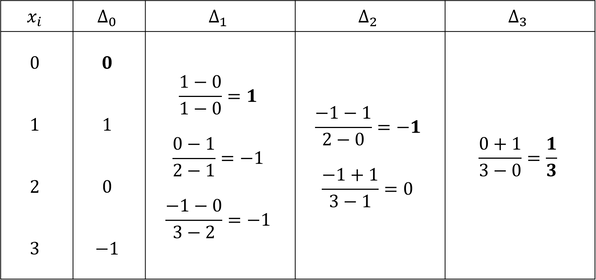

*Таблица разделённых разностей к решению задачи 2*

Выписываем интерполяционный полином в форме Ньютона (вариант "вперёд") по первой косой строке таблицы:

$$P_3(x)=0+1\cdot (x-0)-1\cdot (x-0)(x-1)+\frac{1}{3}\cdot(x-0)(x-1)(x-2)=\frac{1}{3}x^3-2x^2+\frac{8}{3}x.$$

Искомая производная:

$$P_3'(x)=x^2-4x+\frac{8}{3};\quad P_3'\bigg(\frac{3}{2}\bigg)=-\frac{13}{12}.$$

Перейдём к построению сплайна $S_3$. Значения функции заданы в $k+1=4$ узлах равномерной сетки с шагом $h=1$. Учитывая значения разделённых разностей второго порядка, приходим к следующей СЛАУ:

$$\begin{pmatrix}
    4 & 1 \\
    1 & 4
  \end{pmatrix}
  \begin{pmatrix}
    c_2 \\
    c_3
  \end{pmatrix}=
  \begin{pmatrix}
    -6 \\
    0
  \end{pmatrix}.
  $$

Её решение:

$$c_2=-\frac{8}{5},\quad c_3=\frac{2}{5}.$$

Два других коэффициента равны нулю (так как строится именно естественный сплайн): $c_1=c_4=0$.

Условие задачи не требует построения всего сплайна (всех трёх его "кусков"). Точка $x=3/2$ попадает в подотрезок $[x_1,x_2]=[1,2]$, поэтому достаточно найти лишь "кусок" $S^{(2)}_3$ ($i=2$). Имеем:

$$b_2=f_2-f_{1}-\frac{2c_2+c_{3}}{3}=-\frac{1}{15},\quad d_2=\frac{c_{3}-c_2}{3}=\frac{2}{3}.$$

(мы учли, что $h=1$). Наконец, $a_2=f_1=1$.

Итак,

$$S^{(2)}_3(x)=1-\frac{1}{15}(x-1)-\frac{8}{5}(x-1)^2+\frac{2}{3}(x-1)^3;$$

$$\Big[S^{(2)}_3(x)\Big]'=2x^2-\frac{36}{5}x+\frac{77}{15},\quad S'_3\bigg(\frac{3}{2}\bigg)=-\frac{7}{6}.$$

В таблице приведены значения функции $f(x)=\sin(\pi x/2)$. Следовательно, $f'(x)=\pi/2\cdot\cos(\pi x/2)$, так что точное значение функции-оригинала есть

$$f'\bigg(\frac{3}{2}\bigg)=\frac{\pi}{2}\cos\frac{3\pi}{4}=-\frac{\pi\sqrt{2}}{4}.$$

Окончательно:

$$f'\bigg(\frac{3}{2}\bigg)=-\frac{\pi\sqrt{2}}{4}\simeq -1,1107,\quad P_3'\bigg(\frac{3}{2}\bigg)=-\frac{13}{12}\simeq -1,0833\quad S'_3\bigg(\frac{3}{2}\bigg)=-\frac{7}{6}\simeq -1,1667.$$

Легко видеть, что погрешность восстановления значения производной с помощью глобальной интерполяции составила около $3\%$, а с помощью локальной — примерно $5\%$.

Искомое значение производной сплайна $S'_3(3/2)$ можно было бы найти с помощью уже знакомого нам класса ```CubicSpline``` — он поддерживает дифференцирование построенных сплайнов с помощью метода ```derivative``` ([документация](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.derivative.html)):

In [10]:
import numpy as np
from scipy.interpolate import CubicSpline

x = [0, 1, 2, 3]
y = [0, 1, 0, -1]

spl1 = CubicSpline(x, y, bc_type='natural')

In [11]:
spl1.derivative()(3/2)

array(-1.16666667)

Можно находить и производные более высоких порядков; для этого методу ```derivative``` нужно передать аргумент — порядок производной (по умолчанию он равен 1):

In [12]:
spl1.derivative(2)(3/2)

array(-1.2)

In [13]:
spl1.derivative(3)(3/2)

array(4.)

In [14]:
spl1.derivative(4)(3/2)

array(0.)

# Часть вторая — Быстрое преобразование Фурье


Предполагается, что читатель знает

* определение ряда Фурье, его комплексную форму и свойства,
* асимптотическую сложность умножения матрицы порядка $N$ на вектор длины $N$.

## Дискретное преобразование Фурье

Рассмотрим **вещественнозначную** функцию $f=f(t)$ с периодом, равным $T$, т.е. функцию, удовлетворяющую условию $f(t+T)=f(t)$ для любого $t\in\mathbb{R}$. Будем считать, что эта функция задана на отрезке $[0,T]$. Тогда в силу периодичности она оказывается заданной и на всей числовой прямой (говорят также, что функция периодически продолжена на всю числовую прямую). Из курса гармонического анализа известно, что при некоторых дополнительных предположениях такую функцию $f=f(t)$ можно разложить в **ряд Фурье**. Мы запишем его в комплексной форме:

$$f(t)=\sum\limits_{k=-\infty}^{\infty} c_k\exp\bigg(i\,\frac{2\pi k}{T}\,t\bigg),\qquad c_k=\frac{1}{T}\int\limits_0^T\mathop{dt}f(t)\exp\bigg(-i\,\frac{2\pi k}{T}\,t\bigg),\qquad k\in\mathbb{Z}.$$

Здесь и далее полагаем, что функция $f=f(t)$ удовлетворяет всем условиям, обеспечивающим сходимость (и даже равномерную сходимость) ряда Фурье. Для простоты можно считать эту функцию достаточно гладкой. Напомним, что коэффициенты $c_k$ называются **коэффициентами Фурье** функции $f=f(t)$. Вообще говоря, они являются комплексными величинами, даже если функция $f=f(t)$ принимает вещественные значения. В этом последнем случае (который нас и интересует) справедливо соотношение

$$c_{k}^*=c_{-k},\qquad k\in\mathbb{Z},$$

непосредственно следующее из формулы для $c_k$.

Пусть на отрезке $[0,T]$ задана равномерная сетка, состоящая из $N$ узлов:

$$t_n=n\,\frac{T}{N},\qquad n=0,\,1,\,\dots,\,N-1.$$

Положим $t=t_n$ в фурье-разложении функции $f=f(t)$. Тогда для её значений в узлах сетки имеем следующее представление:

$$f_n\equiv f(t_n)=\sum\limits_{k=-\infty}^{\infty}c_k\exp\bigg(i\,\frac{2\pi k}{N}\,n\bigg)\equiv\sum\limits_{k=-\infty}^{\infty}c_kw_N^{kn}.$$

В этой формуле мы для краткости ввели обозначение

$$w_N=\exp\bigg(i\,\frac{2\pi}{N}\bigg).$$

Далее нам часто придётся преобразовывать выражения, содержащие **целые** степени величины $w_N$, поэтому сразу отметим некоторые свойства таких степеней.

**Свойство 1** — целочисленная периодичность:

$$w_N^{(k+k'N)(n+n'N)}=w_N^{kn+(kn'+k'n+k'n'N)N}=w_N^{kn}\cdot\exp\big(2\pi i(kn'+k'n+k'n'N)\big)=w_N^{kn},\quad k,n,k',n'\in\mathbb{Z}.$$

**Свойство 2** — правило понижения степени:

$$w_N^{kn}=\exp\bigg(i\,\frac{2\pi k}{N}\,n\bigg)=\exp\bigg(i\,\frac{2\pi}{N/k}\,n\bigg)=w_{N/k}^n,\qquad k,n\in\mathbb{Z},\qquad k\neq 0.$$

**Свойство 3** — правило сдвига на половину периода:

$$w_N^{k\pm N/2}=\exp\bigg(i\,\frac{2\pi k}{N}\bigg)\cdot\exp\bigg(\pm i\,\frac{2\pi}{N}\frac{N}{2}\bigg)=\exp(\pm \pi i)\cdot\exp\bigg(i\,\frac{2\pi k}{N}\bigg)=-w_{N}^k,\qquad k\in\mathbb{Z}.$$

**Свойство 4** — правило комплексного сопряжения:

$$\big(w_N^{k}\big)^*=\exp\bigg(-i\,\frac{2\pi k}{N}\bigg)=w_{N}^{-k},\qquad k\in\mathbb{Z}.$$

Разумеется, последние три свойства справедливы не только для целых $n$ и $k$.

Вернёмся к написанной выше формуле для $f_n$. В ней индекс суммирования $k$ пробегает все целые числа, поэтому можно положить

$$k=pN+q,\qquad p\in\mathbb{Z},\qquad q=0,\,1,\,\dots,\, N-1.$$

Значит,

$$
\begin{gather}
f_n=\sum\limits_{p=-\infty}^{\infty}\sum\limits_{q=0}^{N-1}c_{pN+q}w_N^{(pN+q)n}=\sum\limits_{q=0}^{N-1}\bigg(\sum\limits_{p=-\infty}^{\infty}c_{pN+q}\bigg)\cdot w_N^{qn}=\\[6pt]
=\frac{1}{N}\sum\limits_{q=0}^{N-1}\bigg(N\cdot\sum\limits_{p=-\infty}^{\infty}c_{pN+q}\bigg)\cdot w_N^{qn}\equiv \frac{1}{N}\sum\limits_{q=0}^{N-1}F_qw_N^{qn}.
\end{gather}
$$

Мы учли свойство периодичности величин $w_N^{qn}$. Множитель $1/N$ введён для удобства дальнейших выкладок.

Полученная формула

$$f_n=\frac{1}{N}\sum\limits_{q=0}^{N-1}F_qw_N^{qn}\equiv\frac{1}{N}\sum\limits_{q=0}^{N-1}F_q\exp\bigg(i\,\frac{2\pi q}{N}\,n\bigg)$$

выступает дискретным аналогом разложения функции $f=f(t)$ в ряд Фурье, поэтому входящую в неё сумму можно назвать **дискретным рядом Фурье**. Величины

$$F_q=N\cdot\sum\limits_{p=-\infty}^{\infty}c_{pN+q},\qquad q=0,\,1,\,\dots,\, N-1,$$

играющие в дискретном случае роль коэффициентов Фурье, естественно назвать **дискретными фурье-компонентами** функции $f=f(t)$ **на (равномерной) сетке из $N$ узлов**. Далее для краткости мы будем называть их просто фурье-компонентами функции $f=f(t)$. Как и коэффициенты Фурье $c_k$, фурье-компоненты $F_q$ являются комплексными числами. Можно показать (мы сделаем это ниже), что если функция $f=f(t)$ вещественнозначна, то $F_q^*=F_{N-q}$.

Итак, зная $N$ фурье-компонент $F_q$ функции $f=f(t)$, мы можем найти $N$ значений этой функции $f_n$ в узлах равномерной сетки, введённой на отрезке периодичности $[0,T]$. Поставим теперь обратную задачу: по известному массиву величин $f_n$ найти массив величин $F_q$.

Для решения этой задачи предварительно заметим, что система из $N$ функций

$$\varphi_q(t)\equiv\exp\bigg(i\,\frac{2\pi q}{T}\,t\bigg),\qquad q=0,\,1,\,\dots,\, N-1,$$

ортогональна на введённой сетке $t_n=nT/N$ в смысле скалярного произведения

$$(\varphi_q, \varphi_s)\equiv\sum\limits_{n=0}^{N-1}\varphi_q(t_n)\varphi_s^*(t_n).$$

Иначе говоря,

$$(\varphi_q, \varphi_s)=N\cdot\delta_{qs},\qquad q,s=0,\,1,\,\dots,\, N-1,$$

где $\delta_{qs}$ — символ Кронекера. В самом деле,

$$\varphi_q(t_n)=w_N^{qn},\qquad\varphi_s^*(t_n)=w_N^{-sn},$$

поэтому

$$(\varphi_q, \varphi_s)=\sum\limits_{n=0}^{N-1}w_N^{(q-s)n}.$$

Если $q=s$, то каждое слагаемое обращается в единицу, а следовательно, сумма оказывается равной числу слагаемых, т.е. $N$. Если же $q\neq s$, то можно применить формулу для суммы первых $N$ членов геометрической прогрессии со знаменателем $w_N^{q-s}$ (и единичным первым членом):

$$(\varphi_q, \varphi_s)=\frac{w_N^{(q-s)N}-1}{w_N^{q-s}-1}=\frac{1-1}{w_N^{q-s}-1}=0.$$

Таким образом, действительно

$$(\varphi_q, \varphi_s)=N\cdot\delta_{qs}.$$

Вернёмся к задаче о выражении фурье-компонент $F_q$ через значения функции $f_n$. В качестве исходного пункта имеем ранее установленное равенство

$$f_n=\frac{1}{N}\sum\limits_{q=0}^{N-1}F_qw_N^{qn}\equiv \frac{1}{N}\sum\limits_{q=0}^{N-1}F_q\varphi_q(t_n).$$

Умножим его на $w_N^{-sn}=\varphi_s^*(t_n)$ и выполним суммирование по $n$, чтобы в правой части получилось уже упоминавшееся скалярное произведение:

$$\sum\limits_{n=0}^{N-1}f_nw_N^{-sn}=\frac{1}{N}\sum\limits_{n=0}^{N-1}\sum\limits_{q=0}^{N-1}F_q\varphi_q(t_n)\varphi_s^*(t_n)=\frac{1}{N}\sum\limits_{q=0}^{N-1}F_q\sum\limits_{n=0}^{N-1}\varphi_q(t_n)\varphi_s^*(t_n)=\frac{1}{N}\sum\limits_{q=0}^{N-1}F_q\cdot(\varphi_q,\varphi_s).$$

Остаётся применить доказанное свойство ортогональности:

$$\sum\limits_{n=0}^{N-1}f_nw_N^{-sn}=\frac{1}{N}\sum\limits_{q=0}^{N-1}F_qN\delta_{qs}=F_s.$$

Переобозначая для единообразия индекс $s$ через $q$, получаем искомую формулу:

$$F_q=\sum\limits_{n=0}^{N-1}f_nw_N^{-nq}.$$

Итак, мы вывели соотношения, которые позволяют переходить от значений периодической функции $f=f(t)$ в узлах равномерной сетки к значениям $F_q$ её фурье-компонент, а также выполнять обратный переход. Выпишем соответствующие формулы ещё раз:

$$F_q=\sum\limits_{n=0}^{N-1}f_nw_N^{-nq},\qquad f_n=\frac{1}{N}\sum\limits_{q=0}^{N-1}F_qw_N^{qn},\qquad w_N=\exp\bigg(i\,\frac{2\pi}{N}\bigg).$$

Преобразование величин $f_n$ в величины $F_q$ называется **прямым дискретным преобразованием Фурье**. Для краткости мы будем использовать аббревиатуру ДПФ; в англоязычной литературе часто встречается аббревиатура DFT — discrete Fourier transform. Если требуется подчеркнуть, что количество величин $f_n$ (и, соответственно, фурье-компонент $F_q$) равно $N$, то говорят о дискретном преобразовании Фурье на $N$ точках (или, коротко, об **$N$-точечном ДПФ**). Преобразование величин $F_q$ в величины $f_n$ называется **обратным дискретным преобразованием Фурье**.

Прямое и обратное ДПФ входят составной частью во многие важные алгоритмы — прежде всего, в алгоритмы цифровой обработки сигналов (модификации ДПФ применяются, например, в алгоритмах сжатия изображений и аудиофайлов). Кроме того, ДПФ находит применение в численных методах математической физики (с его помощью можно решать некоторые краевые задачи для уравнений эллиптического типа).

Отметим, что формулы ДПФ, встречающиеся в литературе, могут отличаться нормировками величин $f_n$ и $F_q$, т.е. множитель $1/N$ может писаться как формуле прямого ДПФ, так и в формуле обратного ДПФ (мы выбрали второй вариант); нормировочный множитель может присутствовать и в обеих формулах в виде $1/\sqrt{N}$. Понятно, что это отличие не является существенным: переход от одной нормировки к другой сводится к переопределению фурье-компонент $F_q$.

Легко видеть, что $N$-точечное ДПФ может быть записано в векторно-матричной форме:

$$\textbf{F}=\textbf{W}\textbf{f}.$$

Здесь $\textbf{f}$, $\textbf{F}$ — векторы (столбцы) длины $N$, составленные из значений функции $f_n$ и фурье-компонент $F_q$ соответственно. Под $\textbf{W}$ понимается симметричная **комплексная** матрица порядка $N$, определяемая равенством $W_{qn}=w_N^{-qn}$, $q,n=0,\,1,\,\dots,\, N-1$:

$$
{\small
\textbf{W}=
  \begin{pmatrix}
      w_N^{-0\cdot 0} & w_N^{-0\cdot 1} & w_N^{-0\cdot 2} & \dots & w_N^{-0\cdot (N-1)} \\
      w_N^{-1\cdot 0} & w_N^{-1\cdot 1} & w_N^{-1\cdot 2} & \dots & w_N^{-1\cdot (N-1)} \\
      w_N^{-2\cdot 0} & w_N^{-2\cdot 1} & w_N^{-2\cdot 2} & \dots & w_N^{-2\cdot (N-1)} \\
      \vdots & \vdots & \vdots & \ddots & \vdots \\
      w_N^{-(N-1)\cdot 0} & w_N^{-(N-1)\cdot 1} & w_N^{-(N-1)\cdot 2} & \dots & w_N^{-(N-1)\cdot(N-1)} \\
  \end{pmatrix}=
  \begin{pmatrix}
      1 & 1 & 1 & \dots & 1 \\
      1 & w_N^{-1} & w_N^{-2} & \dots & w_N^{-(N-1)} \\
      1 & w_N^{-2} & w_N^{-4} & \dots & w_N^{-2(N-1)} \\
      \vdots & \vdots & \vdots & \ddots & \vdots \\
      1 & w_N^{-(N-1)} & w_N^{-2(N-1)} & \dots & w_N^{-(N-1)^2} \\
  \end{pmatrix}.
}$$

Ясно, что обратное ДПФ осуществляется при помощи комплексно сопряжённой матрицы $\textbf{W}^*$:

$$\textbf{f}=\frac{1}{N}\textbf{W}^*\textbf{F}.$$

Это равенство эквивалентно равенству

$$\textbf{f}^{\,*}=\frac{1}{N}\textbf{W}\textbf{F}^*.$$

Иначе говоря, обратное ДПФ, переводящее вектор фурье-компонент $\textbf{F}$ в вектор значений функции $\textbf{f}$, можно рассматривать как прямое ДПФ, осуществляемое над вектором $\textbf{F}^*/N$. При такой трактовке нужно только не забывать, что для получения вектора $\textbf{f}$ к результату преобразования надо применять операцию комплексного сопряжения.

До сих пор мы рассматривали ДПФ в качестве варианта "обычного" ряда Фурье, специально приспособленного к дискретному случаю (для расчётов на компьютере). Именно поэтому исходным объектом в наших построениях была периодическая функция $f=f(t)$, которая после дискретизации превратилась в массив значений $f_n$. Этот массив был конечным и имел длину $N$ — по числу узлов равномерной сетки, попадающих в отрезок периодичности функции $[0,T]$. Соответственно, мы имели $N$ фурье-компонент $F_q$.

Можно было бы ввести прямое и обратное ДПФ формально, взяв выписанные выше формулы для $F_q$ и $f_n$ за определения (как часто и делается в литературе). При таком подходе исходным объектом является конечная (длины $N$) последовательность значений $f_n$ (не связанная ни с какой периодической функцией), по которой определяется **счётный** набор фурье-компонент $F_q$:

$$F_q=\sum\limits_{n=0}^{N-1}f_nw_N^{-nq},\qquad q\in\mathbb{Z}.$$

Правда, пользуясь свойством периодичности величин вида $w_N^{-nq}$, мы немедленно устанавливаем, что

$$F_{q+kN}=\sum\limits_{n=0}^{N-1}f_nw_N^{-n(q+kN)}=\sum\limits_{n=0}^{N-1}f_nw_N^{-nq}=F_q,\qquad k\in\mathbb{Z},$$

так что различных фурье-компонент $F_q$ всё равно оказывается лишь $N$, как и при рассмотрении периодической функции. Аналогичным образом показывается, что из определения обратного ДПФ вытекает периодичность величин $f_n$: $f_{n+kN}=f_n$, $k\in\mathbb{Z}$. Другими словами, последовательность $f_n$ можно считать не конечной, а счётной, но при этом периодической (с периодом $N$). Это снова возвращает нас к трактовке величин $f_n$ в качестве выборки из континуального множества значений периодической функции $f=f(t)$ на отрезке периодичности $[0,T]$.

Руководствуясь приведёнными соображениями, можно распространить формулу

$$F_q=N\cdot\sum\limits_{p=-\infty}^{\infty}c_{pN+q},$$

полученную дискретизацией "обычного" ряда Фурье функции $f=f(t)$, на произвольные целые $q$ (выше данная формула рассматривалась только для $N$ значений индекса $q$). Если мы полагаем $q\in\mathbb{Z}$, то из свойства периодичности легко выводится, что $F_q^*=F_{N-q}$ при $f^*(t)=f(t)$ (это свойство фурье-компонент уже отмечалось ранее). В самом деле,

$$F_q^*=N\cdot\sum\limits_{p=-\infty}^{\infty}c_{pN+q}^*=N\cdot\sum\limits_{p=-\infty}^{\infty}c_{-pN-q}=N\cdot\sum\limits_{p'=\infty}^{-\infty}c_{p'N-q}=N\cdot\sum\limits_{p=-\infty}^{\infty}c_{pN-q}=F_{-q}=F_{N-q}.$$

В этой цепочке равенств применено свойство коэффициентов Фурье действительнозначной функции и выполнена замена индекса $p'=-p$ с последующим переобозначением $p'$ через $p$; на последнем шаге использована периодичность фурье-компонент. Таким образом, **если ДПФ применяется к массиву вещественных чисел, то не требуется вычислять все $N$ величин $F_q$ — достаточно найти лишь первые $N/2 + 1$ (при чётном $N$) или первые $(N+1)/2$ (при нечётном $N$) из них; остальные фурье-компоненты можно получить операцией комплексного сопряжения**. Этим часто пользуются на практике для сокращения объёма вычислений. В частности, если нас интересуют не сами фурье-компоненты $F_q$, а только их модули, то не нужно даже выполнять комплексное сопряжение; грубо говоря, надо найти лишь одну половину массива $|F_q|$, поскольку элементы из другой его половины будут совпадать с найденными. Можно указать и ещё одно следствие доказанного свойства: если $f^*(t)=f(t)$, то $F_0^*=F_N=F_0$, т.е. **нулевая фурье-компонента $F_0$ любой действительнозначной функции $f=f(t)$ вещественна**.

Отметим, что равенство $F_q^*=F_{N-q}$ для фурье-компонент, полученных из действительных значений $f_n$, можно было бы доказать иначе — без ссылки на периодичность величин $F_q$ и свойство коэффициентов Фурье $c_k$.

**Упражнение 3.** Повторить доказательство соотношения $F_q^*=F_{N-q}$ ($q=0,\,1,\,2,\,\dots,\,N-1$) для фурье-компонент вещественнозначной функции $f=f(t)$, **не пользуясь** свойством периодичности величин $F_{q}$ и свойством коэффициентов Фурье $c_k$.

*Указание.* Следует начать с комплексного сопряжения равенства

$$f_n=\frac{1}{N}\sum\limits_{q=0}^{N-1}F_qw_N^{qn}.$$

**Упражнение 4.** Пусть $f_n$ и $g_n$ — два массива **действительных** чисел одинаковой длины $N$. Требуется найти соответствующие им массивы фурье-компонент $F_q$ и $G_q$. Если считать последовательности $f_n$ и $g_n$ независимыми, то понадобится рассчитать два $N$-точечных ДПФ. Можно ли решить ту же задачу выполнением только одного $N$-точечного ДПФ? Как это сделать?

*Указание.* Что получится, если положить $z_n=f_n+i\cdot g_n$ и рассчитать фурье-компоненты $Z_q$? Что можно сказать об элементах массивов $Z_q$, $F_q$ и $G_q$? Как связаны их действительные и мнимые части?

Упомянутый формальный подход к определению ДПФ хорош тем, что его можно без труда обобщить на многомерный случай. Например, можно определить **двумерное ДПФ** для матрицы $m_{nn'}$ порядка $N$:

$$M_{qq'}=\sum\limits_{n=0}^{N-1}\sum\limits_{n'=0}^{N-1}m_{nn'}w_N^{-nq}w_N^{-n'q'},\qquad q,\,q'\in\mathbb{Z}.$$

Очевидно, что фурье-компоненты $M_{qq'}$ оказываются периодичными, как и в одномерном случае:

$$M_{q+kN,\,q'+k'N}=M_{qq'},\qquad k,\,k'\in\mathbb{Z}.$$

Отметим, что матрицы $m_{nn'}$, $M_{qq'}$ могут быть и прямоугольными — размера $N_1\times N_2$. Тогда определение двумерного ДПФ выглядит так:

$$M_{qq'}=\sum\limits_{n=0}^{N_1-1}\sum\limits_{n'=0}^{N_2-1}m_{nn'}w_{N_1}^{-nq}w_{N_2}^{-n'q'},\qquad M_{q+kN_1,\,q'+k'N_2}=M_{qq'}.$$

**Упражнение 5.** Оценить количество операций, необходимых для выполнения двумерного ДПФ над матрицей $N_1\times N_2$, если расчёт осуществляется по определению (непосредственным суммированием).

## Применение дискретного преобразования Фурье для умножения многочленов

Приведём пример практического применения ДПФ — покажем, что на его основе можно построить алгоритм умножения многочленов.

Пусть $P_{N-1}=P_{N-1}(x)$ — многочлен степени $N-1$:

$$P_{N-1}(x)=\sum\limits_{n=0}^{N-1}p_nx^n.$$

Рассмотрим значения этого многочлена в точках $x_q=w_{N}^{-q}$, $q=0,\,1,\,2,\,\dots,\,N-1$:

$$P_{N-1}(x_q)=\sum\limits_{n=0}^{N-1}p_nw_N^{-nq}.$$

Легко видеть, что в правой части получились фурье-компоненты $P_q$, вычисленные по массиву $p_n$. Таким образом,

$$P_q=P_{N-1}(w_{N}^{-q}),\qquad q=0,\,1,\,2,\,\dots,\,N-1,$$

т.е. применение ДПФ к массиву коэффициентов $p_n$ многочлена $P_{N-1}(x)$ степени $N-1$ даёт нам $N$ значений этого многочлена в точках $x_q=w_{N}^{-q}$. Отсюда следует, что **обратное ДПФ позволяет по значениям многочлена $P_{N-1}(x)$ в точках $x_q=w_{N}^{-q}$ восстановить коэффициенты $p_n$ этого многочлена**.

Предположим теперь, что имеются два многочлена степеней $k$ и $l$ соответственно: $P_{k}=P_{k}(x)$ и $Q_{l}=Q_{l}(x)$. Их произведение $P_{k}(x)\cdot Q_{l}(x)$ есть, очевидно, многочлен $R_{k+l}=R_{k+l}(x)$ степени $k+l$. Для удобства введём обозначение $N\equiv k+l+1$, т.е. положим $N-1\equiv k+l$. Ясно, что

$$R_{k+l}(x_q)\equiv R_{N-1}(x_q)=P_{k}(x_q)\cdot Q_{l}(x_q),\qquad x_q=w_{N}^{-q},\qquad q=0,\,1,\,2,\,\dots,\,N-1.$$

Но мы видели, что по массиву значений $R_{N-1}(x_q)$ можно восстановить коэффициенты $r_n$ многочлена $R_{N-1}(x)$.

Сделанные наблюдения позволяют предложить следующий алгоритм вычисления коэффициентов многочлена-произведения $R_{k+l}(x)=P_{k}(x)\cdot Q_{l}(x)$:

* находим значения многочленов-сомножителей $P_{k}(x)$ и $Q_{l}(x)$ в точках $x_q=w_{N}^{-q}$, где $N=k+l+1$, $q=0,\,1,\,2,\,\dots,\,N-1$,

* перемножаем найденные значения **попарно**, образуя массив $R_q$: $R_q=P_{k}(x_q)\cdot Q_{l}(x_q)$,

* выполняем над массивом $R_q$ **обратное** ДПФ и получаем массив $r_n$ (длины $N-1=k+l$) искомых коэффициентов многочлена $R_{k+l}(x)$.

Предложенный алгоритм может показаться бесполезным за счёт искусственного включения в него обратного ДПФ. Однако в действительности сведение задачи об умножении многочленов к задаче о выполнении ДПФ имеет смысл. Если для расчёта ДПФ на третьем шаге используется достаточно быстрый алгоритм, то асимптотически вся процедура может оказаться менее сложной (в смысле числа операций), чем непосредственный подсчёт коэффициентов многочлена-произведения. Далее мы рассмотрим быстрые алгоритмы ДПФ, позволяющие построить метод умножения многочленов со сложностью $O(N\log N)$, в то время как вычисление многочлена-произведения "в лоб" имеет сложность $O(N^2)$.

Отметим, что предложенный алгоритм можно использовать и для умножения двух чисел, записанных в произвольной системе счисления. Если $d\in\mathbb{N}$ — основание системы счисления, то число

$$
\overline{p_{M-1}p_{M-2}\dots p_1p_0}_{d}
$$

можно трактовать как значение многочлена

$$
P_{M-1}(x)=\sum_{m=0}^{M-1}p_mx^m,
$$

в точке $x=d$. Здесь $p_m\in\mathbb{Z}$, $0\leq p_m< d$.

Коэффициенты $r_n$ многочлена-произведения $R_{N-1}(x)$, полученного по описанному выше алгоритму, могут превзойти основание системы счисления $d$ (или оказаться равными ему); ясно, что такие коэффициенты не могут выступать в качестве цифр числа. В подобных случаях выполняют переносы от младших разрядов к старшим:

$$
r_{n+1}\leftarrow r_{n+1}+\left\lfloor\frac{r_n}{d}\right\rfloor,
\qquad
r_n\leftarrow r_n\bmod d.
$$

Переносы продолжают до тех пор, пока все коэффициенты не будут удовлетворять условию $0\leq r_n<d$. Если после обработки старшего коэффициента остаётся ненулевой перенос, к массиву добавляют новые разряды. Полученные коэффициенты являются цифрами искомого числа-произведения.

## Программная реализация дискретного преобразования Фурье

Рассмотрим вопрос о программной реализации ДПФ. На первый взгляд может показаться, что она осуществляется очень просто — достаточно создать матрицу $\textbf{W}$ и воспользоваться приведёнными выше векторно-матричными формулами ДПФ. Например, в случае прямого преобразования программа может иметь такой вид:

In [15]:
import numpy as np

def simple_DFT(f: np.ndarray):
    N = f.shape[0]
    deg = np.arange(N)
    deg = deg[:, np.newaxis] * deg
    W = np.exp(-2j * np.pi / N * deg)

    return np.dot(W, f)

Однако этот алгоритм неэкономичен, поскольку он сводится к умножению матрицы порядка $N$ на вектор длины $N$, а такое умножение требует, как известно, примерно $2N^2$ операций (с комплексными числами); значит, сложность предложенного алгоритма есть $O(N^2)$. Умножение двух комплексных чисел с вычислительной точки зрения "стоит дороже" их сложения или вычитания, поэтому в литературе часто оценивают не общее количество операций, а только количество умножений: их в данном случае получается $N^2$. Так или иначе, непосредственное вычисление ДПФ имеет сложность $O(N^2)$. Подчеркнём, что для простоты мы не учитываем операций, связанных с вычислением величин $w_N^{-qn}$, т.е. матрицу $\textbf{W}$ мы считаем заданной (заранее построенной).

В неэффективности написанной программы можно убедиться и на конкретном примере: возьмём $N=2^{14}\sim 10^4$ и случайный вектор $\textbf{f}$. Вычисление вектора фурье-компонент $\textbf{F}$ потребует порядка 10—20 секунд — это очень много:

In [16]:
f_large = np.random.random(2**14)

%time F_large = simple_DFT(f_large)

CPU times: user 15 s, sys: 4.4 s, total: 19.4 s
Wall time: 23.5 s


In [17]:
F_large

array([8158.17564814 +0.j        ,  -37.11345484+42.01698493j,
         21.62073545-25.46098194j, ...,  -37.93964514+16.40101845j,
         21.62073545+25.46098194j,  -37.11345483-42.01698493j])

Возникает естественный вопрос: нельзя ли предложить более эффективную процедуру вычисления фурье-компонент $F_q$? Оказывается, можно.

## Алгоритм Кули—Тьюки

Вернёмся к покомпонентной формуле прямого ДПФ:

$$F_q=\sum\limits_{n=0}^{N-1}f_nw_N^{-nq},\qquad w_N=\exp\bigg(i\,\frac{2\pi}{N}\bigg).$$

В основе эффективного алгоритма вычисления этой суммы лежит довольно простая идея, которую мы предварительно проиллюстрируем в одном частном случае. Нам понадобится упоминавшееся выше свойство периодичности фурье-компонент, поэтому выпишем его ещё раз:

$$F_{q+kN}=F_q,\qquad k\in\mathbb{Z}.$$

### Быстрое преобразование Фурье по основанию два с прореживанием по времени

Пусть число $N$ чётно. Тогда сумму по $n$ (в которой всего $N$ слагаемых) можно разбить на две суммы, содержащие одинаковое количество слагаемых $N/2$. В первую сумму отнесём члены с чётными $n=2k$, а во вторую — с нечётными $n=2k+1$:

$$F_q=\sum\limits_{k=0}^{N/2-1}f_{2k}w_N^{-2kq}+\sum\limits_{k=0}^{N/2-1}f_{2k+1}w_N^{-(2k+1)q}=\sum\limits_{k=0}^{N/2-1}f_{2k}w_{N/2}^{-kq}+w_N^{-q}\cdot\sum\limits_{k=0}^{N/2-1}f_{2k+1}w_{N/2}^{-kq}.$$

Здесь применено одно из свойств величин вида $w_N^{kq}$ — правило понижения степени. Вводя обозначения

$$f^{(0)}_k=f_{2k},\qquad f^{(1)}_k=f_{2k+1},\qquad k=0,\,1,\,2,\,\dots,\,N/2-1,$$

получаем:

$$F_q=\sum\limits_{k=0}^{N/2-1}f^{(0)}_k w_{N/2}^{-kq}+w_N^{-q}\cdot\sum\limits_{k=0}^{N/2-1}f^{(1)}_kw_{N/2}^{-kq}\equiv F_q^{(0)}+w_N^{-q}\cdot F_q^{(1)}.$$

Как видим, нам удалось разбить $N$-точечное ("большое") ДПФ, применяемое к последовательности (массиву) $f_n$, на два $N/2$-точечных ("малых") ДПФ, применяемых к последовательностям $f_k^{(0)}$ и $f_k^{(1)}$.

В силу свойства периодичности фурье-компонент $F_q^{(0)}$ и $F_q^{(1)}$ имеем:

$$F_{q+N/2}=F_{q+N/2}^{(0)}+w_N^{-(q+N/2)}\cdot F_{q+N/2}^{(1)}=F_q^{(0)}+w_N^{-(q+N/2)}\cdot F_{q}^{(1)}.$$

Положим $q'=q+N/2$:

$$F_{q'}=F_{q'-N/2}^{(0)}+w_N^{-q'}\cdot F_{q'-N/2}^{(1)}.$$

Согласно правилу сдвига на половину периода, $w_N^{-q'}=-w_N^{-q'+N/2}=-w_N^{-(q'-N/2)}$. Переобозначая индекс $q'$ через $q$, приходим к следующему результату:

$$F_{q}=F_{q-N/2}^{(0)}-w_N^{-(q-N/2)}\cdot F_{q-N/2}^{(1)}.$$

Таким образом,

$$
F_{q}=
\begin{cases}
  F_q^{(0)}+w_N^{-q}\cdot F_q^{(1)},\\[6pt]
  F_{q-N/2}^{(0)}-w_N^{-(q-N/2)}\cdot F_{q-N/2}^{(1)}.
\end{cases}
$$

При $q\in\mathbb{Z}$ обе строки в приведённом равенстве совершенно эквивалентны, поскольку вторая формула получена равносильными преобразованиями первой. Потребуем теперь, чтобы значения $q$ не выводили нас за пределы одного периода всех трёх последовательностей фурье-компонент. Тогда следует считать, что $0\leq q\leq N-1$, причём на первой половине периода (при $0\leq q\leq N/2-1$) надо пользоваться первой строкой, а на второй половине (при $N/2\leq q\leq N-1$) — второй. В этом случае в левой части будут получаться величины $F_0$, $F_1$ и т.д. до $F_{N-1}$, т.е. мы "пройдём" один период последовательности $F_q$ целиком (нам попадутся все $N$ элементов, входящих в этот период, и не встретятся никакие элементы соседних периодов). В правой же части будут возникать пары величин $F_0^{(0)}$ и $F_0^{(1)}$, $F_1^{(0)}$ и $F_1^{(1)}$ и т.д. до $F_{N/2-1}^{(0)}$ и $F_{N/2-1}^{(1)}$. Мы снова "пройдём" все значения, составляющие один период последовательностей $F_q^{(0)}$ и $F_q^{(1)}$, — их будет по $N/2$ в обоих случаях — и не встретим ни одного значения, принадлежащего соседним периодам. Если бы мы попытались использовать, например, первую строку формулы не только при $0\leq q\leq N/2-1$, но и, скажем, при $q=N/2+1$, то в правой части нам попались бы величины $F_{N/2+1}^{(0)}$ и $F_{N/2+1}^{(1)}$, принадлежащие уже не тому же периоду, что и первые $N/2$ элементов последовательностей $F_{q}^{(0)}$ и $F_{q}^{(1)}$, а следующему за ним периоду. Но подобный выход за рамки одного периода неоправдан, поскольку для задания каждой из последовательностей $F_{q}^{(0)}$, $F_{q}^{(1)}$ достаточно одного периода; при программной реализации расчёта такой выход означал бы неразумное расходование памяти.

Итак, окончательно

$$
F_{q}=
\begin{cases}
  F_q^{(0)}+w_N^{-q}\cdot F_q^{(1)}, & 0\leq q\leq N/2-1;\\[6pt]
  F_{q-N/2}^{(0)}-w_N^{-(q-N/2)}\cdot F_{q-N/2}^{(1)}, & N/2\leq q\leq N-1.
\end{cases}
$$

Ориентируясь на эту формулу, можно предложить следующий алгоритм вычисления фурье-компонент $F_q$ **при чётном $N$**:

* по исходному массиву $f_n$ значений функции $f=f(t)$ в $N$ узлах равномерной сетки строим два массива длины $N/2$: $f^{(0)}_k=f_{2k}$ и $f^{(1)}_k=f_{2k+1}$, $k=0,\,1,\,2,\,\dots,\,N/2-1$,

* выполняем "малые" ДПФ над каждым из массивов $f^{(0)}_k$ и $f^{(1)}_k$ — в результате получаем массивы фурье-компонент $F_q^{(0)}$ и $F_q^{(1)}$ (каждый имеет длину $N/2$, поскольку $q=0,\,1,\,2,\,\dots,\,N/2-1$),

* вычисляем элементы искомого массива фурье-компонент $F_q$ (длины $N$), пользуясь выведенной формулой.

Предположим, что на втором этапе этого алгоритма "малые" ДПФ выполняются по определению — путём непосредственного вычисления сумм, входящих в выражения для фурье-компонент $F_q^{(0)}$ и $F_q^{(1)}$. Тогда каждое из этих ДПФ требует примерно $2\cdot (N/2)^2=N^2/2$ операций, а оба ДПФ вместе — $N^2$ операций. Сборка массива $F_q$ из массивов $F_q^{(0)}$ и $F_q^{(1)}$ на третьем этапе требует ещё $3N/2$ операций. Действительно, выведенная выше формула предписывает при каждом из $N$ значений индекса $q$ совершить по одному умножению и одному сложению (или вычитанию), но среди $N$ умножений уникальными оказываются лишь $N/2$, поскольку каждое умножение встречается дважды (например, при $q=1$ и $q=N/2+1$ возникает одно и то же умножение $w_N^{-1}\cdot F_1^{(1)}$). Таким образом, полное количество арифметических операций в предложенном алгоритме оценивается величиной $N^2+3N/2$ (при грамотной реализации — без дублирования умножений). Если бы "большое" ДПФ выполнялось напрямую, то оно потребовало бы $2N^2$ операций. Можно, как уже отмечалось, оценивать только количество умножений: их потребуется $2\cdot (N/2)^2 + N/2=N^2/2+N/2$, если пользоваться предложенным алгоритмом, и $N^2$, если вычислять исходное ДПФ "в лоб". Из обеих оценок следует, что **если число $N$ достаточно велико** ($N^2\gg 3N/2$, т.е. $N\gtrsim 20$), **то переход к предложенному алгоритму позволяет сократить количество операций вдвое**.



Дальнейшее развитие рассмотренного алгоритма очевидно. Если число $N/2$ (количество значений, принимаемых на вход "малыми" ДПФ) тоже оказалось чётным, то "малые" ДПФ могут быть выполнены по аналогичной схеме: каждый из массивов $f_k^{(0)}$, $f_k^{(1)}$ длины $N/2$ разбивается на два подмассива длины $N/4$ (выделяются элементы с чётными и нечётными индексами $k$), для всех четырёх "кусков" выполняются ДПФ, после чего сначала собираются массивы $F_q^{(0)}$, $F_q^{(1)}$ (по формуле, аналогичной выведенной выше), а затем из этих массивов собирается искомый массив $F_q$ (уже в точности по той формуле, которая выводилась). Если и число $N/4$ оказалось чётным, то выполнение ДПФ для четырёх массивов длины $N/4$ тем же приёмом сводится к ДПФ для восьми массивов вдвое меньшей длины $N/8$ и т.д. Одним словом, вся процедура строится рекурсивно.

Разбиение данного массива (из чётного числа элементов) на два массива вдвое меньшей длины путём выбора элементов с чётными и нечётными номерами называют **прореживанием**. Понятно, что в описанном рекурсивном алгоритме прореживание можно проводить ровно до тех пор, пока на очередном этапе не получатся массивы с нечётным числом элементов. Для таких массивов ДПФ придётся осуществлять уже по определению (прямым вычислением суммы); когда это будет сделано, для завершения расчёта останется вернуться к массиву исходной длины путём последовательной сборки фурье-компонент.

Особый интерес представляет случай, когда число $N$ является степенью двойки: $N=2^d$. В этом случае прореживание может быть проведено вплоть до получения $N$ тривиальных массивов, каждый из которых включает по одному элементу. Вычисление ДПФ по таким "массивам" не требует никаких арифметических операций, поскольку при $N=1$ из определения прямого ДПФ исчезает сумма:

$$F_0=f_0w_1^{-0\cdot 0}=f_0.$$

Таким образом, если $N=2^d$, то из предложенного рекурсивного алгоритма выпадает стадия осуществления ДПФ по определению; весь расчёт сводится к перенумерации компонент исходного массива $f_n$ значений функции $f=f(t)$ и последующей поэтапной сборке фурье-компонент. Соответствующий алгоритм можно изобразить наглядно при помощи особого графа. Поясним, как он строится, на примере восьмиточечного ДПФ.

На вход алгоритма подаётся массив из восьми значений функции $f_n$:

$$f_n=[f_0,\quad f_1,\quad f_2,\quad f_3,\quad f_4,\quad f_5,\quad f_6,\quad f_7].$$

Выполняем первое прореживание — выделяем из $f_n$ элементы с чётными и нечётными индексами. В результате получаем два массива $f^{(0)}_k$ и $f^{(1)}_k$ из четырёх элементов:

$$f_k^{(0)} = [f_0,\quad f_2,\quad f_4,\quad f_6],\qquad f_k^{(1)} = [f_1,\quad f_3,\quad f_5,\quad f_7].$$

После второго прореживания имеем четыре массива из двух элементов:

$$f_j^{(00)} = [f_0,\quad f_4],\qquad f_j^{(01)} = [f_2,\quad f_6],\qquad f_j^{(10)} = [f_1,\quad f_5],\qquad f_j^{(11)} = [f_3,\quad f_7].$$

Подчеркнём, что при выполнении второго прореживания мы ориентируемся на чётность или нечётность индекса $k$ в массивах $f_k^{(0)}$ и $f_k^{(1)}$, т.е. отбираем элементы с чётных и нечётных мест **в этих двух массивах**. Чётность или нечётность индекса $n$ при **втором** прореживании значения уже не имеет. Например, массив $f_j^{(01)}$ получается отбором элементов массива $f_k^{(0)}$ с **нечётных** мест, т.е. с первого ($k=1$) и третьего ($k=3$) мест (поскольку нумерация мест начинается с нуля). На этих местах в массиве $f_k^{(0)}$ стоят элементы $f_2$ и $f_6$ соответственно; именно они и попадают в массив $f_j^{(01)}$, хотя первоначальный индекс — индекс $n$ — у этих элементов **чётный** ($n=2$ и $n=6$ соответственно). По тому же принципу выполняются и все последующие прореживания.

Наконец, третье (и последнее) прореживание приводит к восьми "массивам" из одного элемента:

$$
\begin{gather}
  f_l^{(000)} = f_0,\quad f_l^{(001)} = f_4,\quad f_l^{(010)} = f_2,\quad f_l^{(011)} = f_6,\\[4pt]
  f_l^{(100)} = f_1,\quad f_l^{(101)} = f_5,\quad f_l^{(110)} = f_3,\quad f_l^{(111)} = f_7.
\end{gather}
$$

Выше при выписывании массивов мы использовали **двоичную индексацию**, принцип построения которой очевиден: каждое прореживание добавляет новый индекс, причём при отборе элементов с чётных мест образующийся массив вдвое меньшей длины помечается нулём, а при отборе элементов с нечётных мест — единицей. Назначение такой индексации станет ясно из дальнейшего.

Заключительное прореживание (в данном случае — третье по счёту) даёт нам в результате некоторую последовательность из элементов исходного массива $f_n$, все члены которой пронумерованы двоичными индексами (имеют определённый двоичный код). Отметим, что двоичный индекс конкретного элемента $f_n$ можно получить сразу, не выполняя промежуточных прореживаний. Для этого номер элемента в массиве $f_n$ (т.е. индекс $n$) необходимо перевести в двоичную систему счисления, а затем инвертировать — переписать в обратном порядке. Возьмём, например, элемент $f_3$. Его индекс $3$ в двоичной системе счисления записывается как $011$. Инвертируя этот двоичный код, получаем $110$. Это и есть двоичный индекс "массива" длины один, в который попадёт элемент $f_3$ после всех прореживаний: $f_l^{(110)}=f_3$. Иначе говоря, номер элемента $f_3$ в последовательности, получаемой после всех прореживаний, будет равен $6$, поскольку $110$ — это двоичная запись десятичного числа $6$ (как обычно, нумерация элементов начинается с нуля). Тот же результат мы получили выше путём последовательных прореживаний. Очевидно, что данное правило — **правило двоичной инверсии** — справедливо и в общем случае (когда $N=2^d$).

Мы уже отметили, что при $N=1$ ДПФ осуществляется тривиально: единственная фурье-компонента совпадает с единственным значением функции. Таким образом, результаты выполнения ДПФ над восемью "массивами" даются той же последовательностью из элементов исходного массива $f_n$ (просто переобозначенной):

$$
\begin{gather}
  F_l^{(000)} = f_0,\quad F_l^{(001)} = f_4,\quad F_l^{(010)} = f_2,\quad F_l^{(011)} = f_6,\\[4pt]
  F_l^{(100)} = f_1,\quad F_l^{(101)} = f_5,\quad F_l^{(110)} = f_3,\quad F_l^{(111)} = f_7.
\end{gather}
$$

Изобразим эту последовательность столбцом точек:

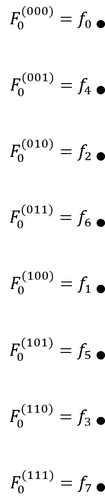

*Построение графа алгоритма быстрого преобразования Фурье: шаг первый — тривиальные ДПФ для восьми массивов длины $N/8=1$*

Из этих восьми "массивов" фурье-компонент теперь необходимо собрать четыре массива фурье-компонент $F_l^{(00)}$, $F_l^{(01)}$, $F_l^{(10)}$, $F_l^{(11)}$. Сборка первого из них осуществляется по формуле

$$
F_{l}^{(00)}=
\begin{cases}
  F_l^{(000)}+w_{N/4}^{-l}\cdot F_l^{(001)}, & 0\leq l\leq N/8-1;\\[6pt]
  F_{l-N/8}^{(000)}-w_{N/4}^{-(l-N/8)}\cdot F_{l-N/8}^{(001)}, & N/8\leq l\leq N/4-1.
\end{cases}
$$

Она совершенно аналогична доказанной выше формуле для $F_q$ и получается из неё заменой $N\to N/4$, а также переобозначением массивов. Введённая нами двоичная индексация позволяет указать очевидное общее правило, по которому легко выписываются все подобные формулы:

$$
F_{l}^{(\bullet)}=
\begin{cases}
  F_l^{(\bullet\,0)}+w_{N'}^{-l}\cdot F_l^{(\bullet\,1)}, & 0\leq l\leq N'/2-1;\\[6pt]
  F_{l-N'/2}^{(\bullet\,0)}-w_{N'}^{-(l-N'/2)}\cdot F_{l-N'/2}^{(\bullet\,1)}, & N'/2\leq l\leq N'-1;
\end{cases}
\qquad N'=N/2^{\text{len}\,\bullet}.
$$

Символ "$\bullet$" означает произвольную последовательность нулей и единиц (двоичный код), а запись $\text{len}\,\bullet$ служит для обозначения длины этой последовательности. Например, если $\bullet=00$, то $\text{len}\,\bullet=2$, $N'=N/4$ и получается выписанная ранее формула сборки массива $F_l^{(00)}$. Если считать $\bullet$ пустой последовательностью (нулевой длины), то получается формула для искомых фурье-компонент $F_q$, выведенная в начале раздела.

Поскольку в рассматриваемом примере $N=8$, каждая из строк формулы для фурье-компонент $F_l^{(00)}$ включает по одному равенству (при $l=0$ и $l=1$). Итого имеем совокупность из двух равенств:

$$
\begin{cases}
  F_{0}^{(00)}=F_0^{(000)}+w_{2}^0\cdot F_0^{(001)}=F_0^{(000)}+F_0^{(001)}=f_0+f_4,\\[6pt]
  F_{1}^{(00)}=F_{0}^{(000)}-w_{2}^{0}\cdot F_{0}^{(001)}=F_{0}^{(000)}-F_{0}^{(001)}=f_0-f_4.
\end{cases}
$$

Преобразование пары (комплексных) чисел $a$, $b$ в пару (комплексных же) чисел $A$, $B$ вида

$$
\begin{cases}
A=a+w_N^{-k}\cdot b,\\[4pt]
B=a-w_N^{-k}\cdot b
\end{cases}
$$

называется **"бабочкой"** (здесь, как и выше, $k\in\mathbb{Z}$, $N\in\mathbb{N}$). Этому преобразованию сопоставляется следующий граф:

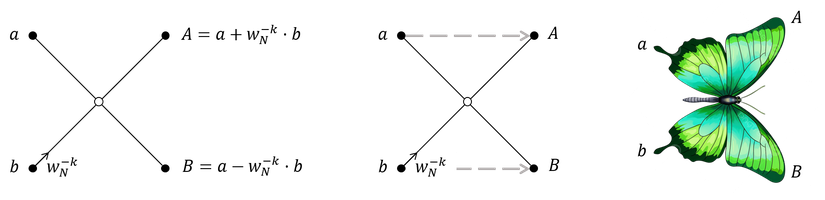

*Граф преобразования "бабочка". На среднем рисунке для наглядности пунктирными стрелками показано направление преобразования*

Приведённый граф читается слева направо (в этом направлении "летит бабочка"). Светлый кружок служит для обозначения операций сложения и вычитания, выполняемых над парой чисел $a$ и $b$, которые подаются на вход преобразования. Стрелка с подписью коэффициента $w_N^{-k}$ указывает, что число $b$ поступает на вход "бабочки" с соответствующим дополнительным множителем. Иногда множитель $w_N^{-k}$ называют **поворачивающим множителем**.

Таким образом, сборка массива $F_l^{(00)}$ — это "бабочка" вида

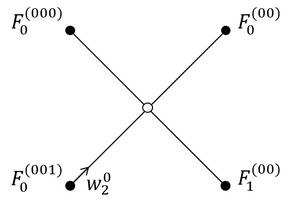

*Пример "бабочки", входящей в алгоритм быстрого преобразования Фурье, — сборка массива $F_l^{(00)}$*

Аналогичными "бабочками" изображаются операции сборки оставшихся трёх массивов: $F_l^{(01)}$, $F_l^{(10)}$ и $F_l^{(11)}$. Например, в случае массива $F_l^{(10)}$ имеем следующую "бабочку":

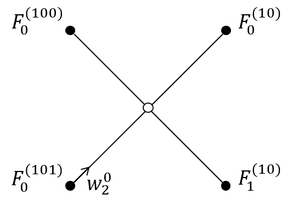

*Ещё один пример "бабочки", входящей в алгоритм быстрого преобразования Фурье, — сборка массива $F_l^{(10)}$*

Для наглядности запишем её же в виде формулы — она получается по изложенному выше общему правилу (полагаем в нём $\bullet=10$ и $N=8$):

$$
\begin{cases}
  F_{0}^{(10)}=F_0^{(100)}+w_{2}^0\cdot F_0^{(101)}=F_0^{(100)}+F_0^{(101)}=f_1+f_5,\\[6pt]
  F_{1}^{(10)}=F_{0}^{(100)}-w_{2}^{0}\cdot F_{0}^{(101)}=F_{0}^{(100)}-F_{0}^{(101)}=f_1-f_5.
\end{cases}
$$

Изобразим все четыре "бабочки", отвечающие операциям сборки массивов $F_l^{(00)}$, $F_l^{(01)}$, $F_l^{(10)}$ и $F_l^{(11)}$, на общем графе рассматриваемого алгоритма:

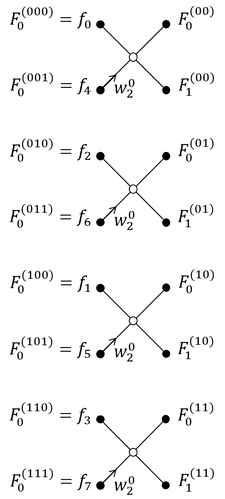

*Построение графа алгоритма быстрого преобразования Фурье: шаг второй — добавлены четыре "бабочки" для сборки четырёх массивов длины $N/4=2$*

Теперь по известным элементам массивов $F_l^{(00)}$, $F_l^{(01)}$, $F_l^{(10)}$, $F_l^{(11)}$ алгоритм должен собрать массивы $F_l^{(0)}$ и $F_l^{(1)}$. Рассмотрим в качестве примера сборку первого из них. По общему правилу получаем формулу сборки ($\bullet=0$, $\text{len}\,\bullet=1$, $N'=N/2$):

$$
F_{l}^{(0)}=
\begin{cases}
  F_l^{(00)}+w_{N/2}^{-l}\cdot F_l^{(01)}, & 0\leq l\leq N/4-1;\\[6pt]
  F_{l-N/4}^{(00)}-w_{N/2}^{-(l-N/4)}\cdot F_{l-N/4}^{(01)}, & N/4\leq l\leq N/2-1.
\end{cases}
$$

В нашем случае $N=8$, поэтому

$$
F_{l}^{(0)}=
\begin{cases}
  F_l^{(00)}+w_{4}^{-l}\cdot F_l^{(01)}, & l=0,\,1;\\[6pt]
  F_{l-2}^{(00)}-w_{4}^{-(l-2)}\cdot F_{l-2}^{(01)}, & l=2,\,3.
\end{cases}
$$

Эта формула содержит четыре равенства, которые мы объединим в две пары (по примеру формул, относящихся к предыдущей стадии алгоритма, одно равенство выбирается из верхней строки, другое — из нижней). При $l=0$ и $l=2$ имеем:

$$
\begin{cases}
  F_{0}^{(0)}=F_0^{(00)}+w_{4}^0\cdot F_0^{(01)}=F_0^{(00)}+F_0^{(01)},\\[6pt]
  F_{2}^{(0)}=F_{0}^{(00)}-w_{4}^{0}\cdot F_{0}^{(01)}=F_{0}^{(00)}-F_{0}^{(01)}.
\end{cases}
$$

Мы получили "бабочку", изображаемую графом


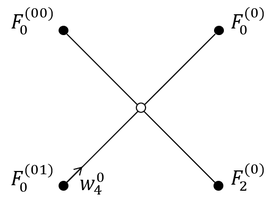

*Одна из "бабочек", входящих в сборку массива $F_l^{(0)}$*

При $l=1$ и $l=3$ имеем:

$$
\begin{cases}
  F_{1}^{(0)}=F_1^{(00)}+w_{4}^{-1}\cdot F_1^{(01)}=F_1^{(00)}-iF_1^{(01)},\\[6pt]
  F_{3}^{(0)}=F_{1}^{(00)}-w_{4}^{-1}\cdot F_{1}^{(01)}=F_{1}^{(00)}+i F_{1}^{(01)}.
\end{cases}
$$

Это — "бабочка" следующего вида:

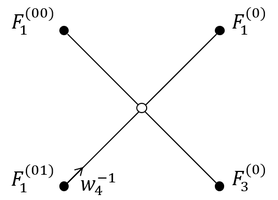

*Вторая "бабочка", входящая в сборку массива $F_l^{(0)}$*

Таким образом, сборка массива $F_l^{(0)}$ — это совокупность из двух бабочек:

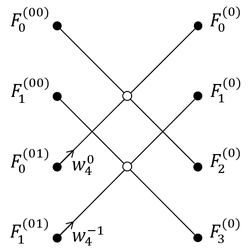

*Граф из двух "бабочек", изображающий сборку массива $F_l^{(0)}$*

Подчеркнём, что операциям "бабочка" на этом графе отвечают только две его вершины, обозначенные светлыми кружками. Прочие пересечения рёбер графа никаких операций не означают.

Читателю предлагается самостоятельно убедиться в том, что сборка массива $F_l^{(1)}$ задаётся аналогичным графом из двух "бабочек":

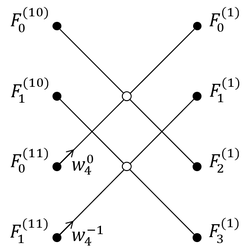

*Граф из двух "бабочек", изображающий сборку массива $F_l^{(1)}$*

Нанесём графы, изображающие операции сборки массивов $F_l^{(0)}$ и $F_l^{(1)}$, на общий граф всего алгоритма:

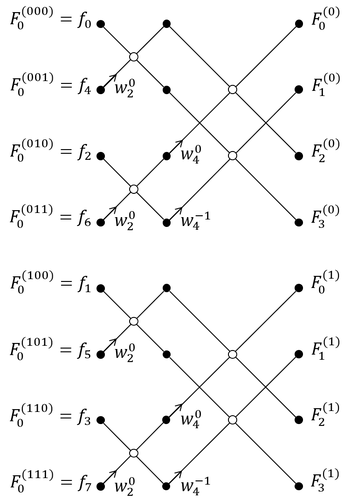

*Построение графа алгоритма быстрого преобразования Фурье при $N=8$: шаг третий — добавлены две группы "бабочек" (каждая включает по две "бабочки") для сборки двух массивов длины $N/2=4$*

Остаётся по найденным элементам массивов $F_l^{(0)}$ и $F_l^{(1)}$ рассчитать искомые фурье-компоненты $F_q$. Соответствующая расчётная формула была выведена нами в начале раздела. Напишем её ещё раз (сразу при $N=8$):

$$
F_{l}=
\begin{cases}
  F_l^{(0)}+w_8^{-l}\cdot F_l^{(1)}, & l=0,\,1,\,2,\,3;\\[6pt]
  F_{l-4}^{(0)}-w_8^{-(l-4)}\cdot F_{l-4}^{(1)}, & l=4,\,5,\,6,\,7.
\end{cases}
$$

Действуя так же, как и выше, можно убедиться в том, что этой формуле соответствует группа из четырёх "бабочек":

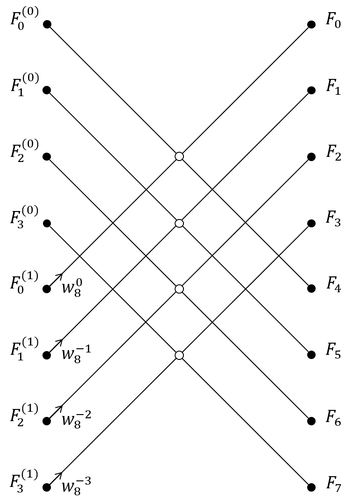

*Граф из четырёх "бабочек", изображающий сборку массива $F_l$*

Изображая эту группу "бабочек" на общем графе, получаем окончательно граф всего алгоритма:

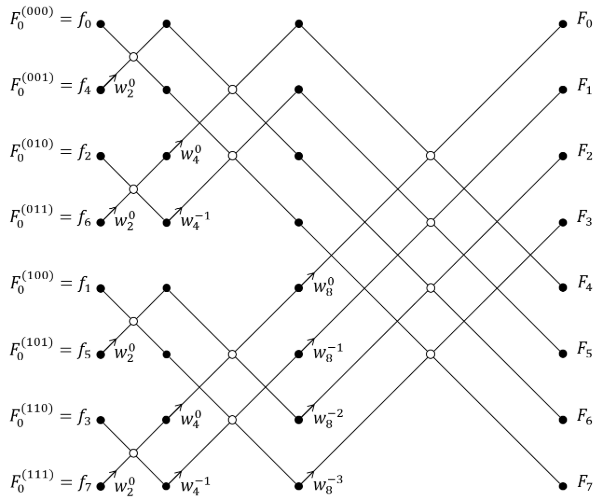

*Построение графа алгоритма быстрого преобразования Фурье при $N=8$: шаг четвёртый (заключительный) — добавлена группа из четырёх "бабочек" для сборки искомого массива фурье-компонент длины $N$*

Как правило, все поворачивающие множители на подобных графах записывают в виде $w_N^{-k}$, избавляясь с помощью правила понижения степени от записей типа $w_{N/2}^{-k}$, $w_{N/4}^{-k}$ и т.д. В нашем случае (при $N=8$) вместо $w_2^0$ на графе лучше написать $w_8^0$, вместо $w_4^{-1}$ — $w_8^{-2}$ и т.д. В итоге граф приобретает следующий вид:

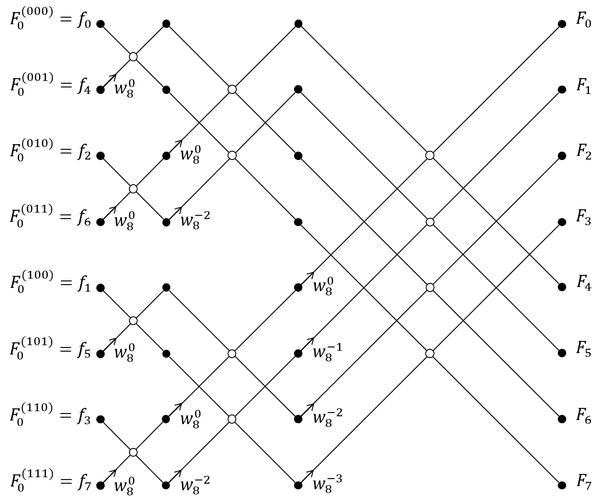

*Граф алгоритма быстрого преобразования Фурье при $N=8$*

Очевидно, что по аналогичной схеме можно вычислить искомые фурье-компоненты $F_q$ при любом $N=2^d$: принцип расчёта не изменяется, от $d$ зависят лишь количество необходимых прореживаний исходного массива $f_n$ и число стадий сборки фурье-компонент (совпадающее с количеством прореживаний). При $d=3$ нам понадобилось три прореживания и, соответственно, три стадии сборки. Глядя на построенный граф, нетрудно заметить, что каждая стадия сборки включала $4=2^{3-1}$ "бабочки", но их группировка менялась от стадии к стадии: сначала мы имели четыре отдельные "бабочки", затем две группы из двух "бабочек" и, наконец, одну группу из четырёх "бабочек". Ясно, что **в общем случае ДПФ на $N=2^d$ точках понадобится $d$ прореживаний и $d$ стадий сборки, причём каждая стадия будет содержать $2^{d-1}$ "бабочек"**.

Вычисление одной "бабочки" включает три операции: умножение (мы считаем, что оно выполняется единожды с запоминанием результата, и поэтому не дублируется), сложение и вычитание. Поэтому общее количество операций в предложенном алгоритме оценивается величиной

$$3\cdot 2^{d-1}\cdot d=\frac{3}{2}\cdot 2^d\cdot d=\frac{3}{2}N\log_2 N.$$

(три операции в каждой из $2^{d-1}$ "бабочек" на каждой из $d$ стадий сборки). Если бы считали только операции умножения, то получили бы $N/2\cdot\log_2 N$. Таким образом, **сложность построенного алгоритма есть $O(N\log N)$**. Напомним, что изменение основания логарифма сводится к его умножению на постоянный множитель, поэтому в асимптотических оценках сложности основание логарифма обычно не уточняется (можно было бы написать $O(N\log_2 N)$ или $O(N\ln N)$ — эти оценки сложности имеют одинаковый смысл).

Следует иметь в виду, что на самом деле количество умножений в предложенном алгоритме оказывается даже меньше, чем $N/2\cdot\log_2 N$. Так, на первой стадии сборки поворачивающие множители всех "бабочек" равны $w_2^0=1$, т.е. в действительности "бабочки" не содержат операций умножения (мы видели это выше, при выписывании конкретных примеров расчётных формул). На второй стадии сборки мы имеем множители $w_8^0=1$, $w_8^{-2}=-i$. Умножение же комплексного числа $a+ib$ на $-i$ сводится к перестановке его вещественной и мнимой частей с изменением знака "новой" мнимой части:

$$-i\cdot (a+ib)=b-ia.$$

Если исходное число было вещественным ($b=0$), то умножение на $-i$ есть просто создание комплексного числа $-ia$. Как видим, в "бабочке" с поворачивающим множителем $w_8^{-2}=-i$ комплексное умножение, по сути, тоже не используется. Вообще говоря, тривиальными оказываются умножения на $w_N^0=1$, $w_N^{-N/2}=-1$, $w_N^{-N/4}=-i$, $w_N^{-3N/4}=i$. В приведённом примере с $N=8$ из $8/2\cdot\log_2 8=12$ умножений нетривиальными оказываются всего два (в "бабочках" третьей стадии сборки с поворачивающими множителями $w_8^{-1}$ и $w_8^{-3}$). В продвинутых реализациях алгоритма тривиальные умножения заменяются более простыми операциями; этим достигается ещё большая оптимизация вычислений. Впрочем, на оценку асимптотической сложности алгоритма подобная оптимизация не влияет.

Итак, вычисление ДПФ путём непосредственного суммирования имеет сложность $O(N^2)$, а вычисление по предложенному алгоритму — сложность $O(N\log N)$. При $N\sim 10^4$ изменение схемы расчёта ускоряет вычисления на три порядка (точнее — примерно в 1500 раз). В силу столь существенной эффективности построенный алгоритм обычно называют **быстрым преобразованием Фурье** (сокращённо — БПФ); в англоязычной литературе используется аббревиатура FFT — fast Fourier transform. Поскольку алгоритм строится при $N=2^d$, говорят о **БПФ по основанию два**. В рассмотренной версии алгоритма прореживания выполнялись в исходном массиве $f_n$, элементы которого обычно истолковываются как значения некоторого сигнала $f=f(t)$ в моменты времени $t_n=nT/N$. Таким образом, полное название алгоритма — **БПФ по основанию два с прореживанием по времени**. Другой вариант БПФ (с прореживанием по частоте) мы рассмотрим ниже.



Предложим программную реализацию БПФ. Составление той части программы, которая ответственна за сборку фурье-компонент (т.е. за сам расчёт "бабочек"), не представляет затруднений: достаточно организовать три вложенных цикла, из которых первый (внешний) предназначен для прохода по стадиям сборки, второй (средний) — для прохода по группам "бабочек" на фиксированной стадии и, наконец, третий (внутренний) — для прохода по "бабочкам" фиксированной группы. Однако запуск этих циклов возможен только после предварительной перестановки элементов входного массива в двоично-инверсном порядке. Таким образом, начинать программу следует с реализации разобранного выше правила двоичной инверсии.

Напишем функцию, вычисляющую по номеру элемента в исходном массиве $f_n$ (т.е. по индексу $n$) номер того же элемента после всех прореживаний:

In [18]:
def binary_reverse(n: int, d: int):
    bin_rev = 0
    for j in range(0, d):
        if n & (1 << j):
            bin_rev |= 1 << (d - 1 - j)

    return bin_rev

Цикл по $j$ предназначен для прохода по двоичным разрядам (начиная с нулевого). Выполняя операцию битового сдвига ```1 << j```, мы получаем двоичное число, у которого в $j$-м разряде стоит единица, а во всех остальных разрядах — нули. Проверяя условие ```n & (1 << j)```, мы устанавливаем, стоит ли единица $j$-м разряде двоичной записи индекса $n$. Если стоит, то в инвертированном двоичном коде необходимо поставить единицу в $j$-й **с конца** разряд. Поскольку общее количество разрядов двоичной записи равно $d$ (так как индекс $n$ в массиве длины $2^d$ пробегает значения от $0$ до $2^d-1$), "обычный" номер $j$-го с конца разряда есть $d - 1 - j$. Строка кода, стоящая под условием в цикле, предназначена для накопления единиц как раз в этих разрядах.

Проверим правильность работы написанной функции на примере с $n=3$ (и $d=3$). Выше мы видели, что элемент с таким индексом после применения правила двоичной инверсии приобретает двоичный код $110$. Иначе говоря, после всех прореживаний этот элемент оказывается на месте с номером $6$ (поскольку $110$ — это двоичная запись числа $6$).

In [19]:
binary_reverse(3, 3)

6

Таким образом, функция работает правильно.

После программной реализации правила двоичной инверсии нетрудно составить всю программу для алгоритма БПФ:

In [20]:
def my_FFT(f: np.ndarray):
    # создаём комплексную копию, чтобы не изменять исходный массив
    f = np.asarray(f, dtype=complex).copy()

    N = f.shape[0]

    # вычисление логарифма log_2(N) — этот алгоритм быстрее вызова np.log2(N)
    d = 0
    while ((1 << d) < N): d += 1

    # перестановка элементов входного массива в двоично-инверсном порядке
    for n in range(0, N):
        if n < binary_reverse(n, d):
            f[[n, binary_reverse(n, d)]] = f[[binary_reverse(n, d), n]]

    for stage in range(1, d+1): # цикл по стадиям сборки
        w_step = np.exp(-2j * np.pi / 2**stage)

        for i in range(0, N, 2**stage): # цикл по группам "бабочек" одной стадии
            w = 1 + 0j

            for j in range(0, 2**(stage-1)): # цикл по "бабочкам" одной группы
                a = f[i + j]
                w_b = f[i + 2**(stage-1) + j] * w

                f[i + j] = a + w_b
                f[i + 2**(stage-1) + j] = a - w_b

                w *= w_step # рекуррентное вычисление поворачивающих множителей

    return f

Программа начинается с перестановки элементов массива в двоично-инверсном порядке: с помощью функции ```binary_reverse``` для элемента с индексом $n$ находится его "новый" индекс $n'$ (индекс, приобретаемый элементом после всех прореживаний), а затем элементы с индексами $n$ и $n'$ меняются местами. Понятно, что индексы $n$ и $n'$ являются как бы **дополнительными друг к другу**: если из индекса $n$ при двоичной инверсии получается индекс $n'$, то из индекса $n'$ при двоичной инверсии получается индекс $n$. Поэтому в программе попарные перестановки элементов массива совершаются лишь при выполнении условия ```n < binary_reverse(n, d)```, т.е. при $n<n'$. Если бы этого условия не было, то в результате прохода по массиву каждая пара элементов переставилась бы дважды, так что в итоге порядок элементов остался бы прежним. Дальнейшая структура программы ясна и без комментариев (про организацию трёх вложенных циклов мы уже говорили выше).

Проверим, что реализованный алгоритм БПФ работает корректно, — вычислим с помощью функции ```my_FFT``` ДПФ для случайного вектора длины $N=32$. Результат сравним с ДПФ, рассчитанным "в лоб" при помощи написанной в предыдущем разделе функции ```simple_DFT```:

In [21]:
f = np.random.random(32)

F_simple = simple_DFT(f)
F_my = my_FFT(f)

In [22]:
np.allclose(F_simple, F_my)

True

Массивы фурье-компонент, полученные двумя функциями, совпали. Значит, алгоритм БПФ реализован верно.

Повторим теперь "экстремальный" тест, с помощью которого ранее была проиллюстрирована неэффективность функции ```simple_DFT``` — попробуем подать на вход функции ```my_FFT``` случайный массив длины $2^{10}$:

In [23]:
f_large = np.random.random(2**10)

%time F_large = my_FFT(f_large)

CPU times: user 9.85 ms, sys: 0 ns, total: 9.85 ms
Wall time: 11.1 ms


In [24]:
len(F_large)

1024

Как видим, алгоритм БПФ вычислил искомые фурье-компоненты за десятые доли секунды, т.е. в сто раз быстрее, чем "наивный" алгоритм с непосредственным суммированием (или перемножением матрицы и вектора). Подчеркнём, что мы предложили далеко не самую совершенную программу. Можно было бы оптимизировать перестановку элементов массива (по-другому реализовать правило двоичной инверсии), организовать иной способ вычисления поворачивающих множителей (чтобы избавиться от лишних умножений) и т.д. Однако даже написанная простая программа даёт значительную экономию времени вычислений. Это доказывает эффективность алгоритма БПФ.

### Быстрое преобразование Фурье по основанию два с прореживанием по частоте

Мы видели, что ключевая идея, используемая при построении алгоритма БПФ по основанию два, состоит в разбиении заданного массива значений функции длины $N$ на два подмассива вдвое меньшей длины $N/2$ (предполагается, что число $N$ чётно). В рассмотренном выше варианте алгоритма это разбиение осуществлялось путём прореживания — отбора элементов с чётных и нечётных мест. Можно было бы, однако, строить подмассивы иначе.

Запишем формулу прямого ДПФ, разделив сумму из $N$ слагаемых на две части: первые $N/2$ слагаемых отнесём в первую сумму, а оставшиеся $N/2$ слагаемых — во вторую. Получим:

$$
\begin{gather}
F_q=\sum\limits_{n=0}^{N/2-1}f_nw_N^{-nq}+\sum\limits_{n=N/2}^{N-1}f_nw_N^{-nq}=\\
=\sum\limits_{n=0}^{N/2-1}f_{n}w_N^{-nq}+\sum\limits_{k=0}^{N/2-1}f_{k+N/2}w_N^{-qN/2}w_N^{-kq}=\sum\limits_{n=0}^{N/2-1}\left(f_n+f_{n+N/2} w_N^{-qN/2}\right)w_N^{-nq}.
\end{gather}
$$

В этой цепочке равенств мы сначала перешли к индексу $k=n-N/2$ во второй сумме, а затем переобозначили индекс $k$ через $n$.

Теперь рассмотрим по отдельности два случая: $q=2k$ и $q=2k+1$. Поскольку $w_N^{-2k\cdot N/2}=w_N^{-kN}=w_N^0=1$, в первом случае имеем:

$$F_{2k}=\sum\limits_{n=0}^{N/2-1}\left(f_n+f_{n+N/2}\right)w_{N/2}^{-nk}.$$

Здесь использовано правило понижения степени, согласно которому $w_{N}^{-2nk}=w_{N/2}^{-nk}$. Аналогично рассматриваем второй случай:

$$F_{2k+1}=\sum\limits_{n=0}^{N/2-1}\left(f_n-f_{n+N/2}\right)w_{N}^{-2nk-n}=\sum\limits_{n=0}^{N/2-1}\left[\left(f_n-f_{n+N/2}\right)w_{N}^{-n}\right]w_{N/2}^{-nk}$$

на основании того, что $w_N^{-(2k+1)\cdot N/2}=w_N^{-kN-N/2}=-w_N^0=-1$ в силу правила сдвига на половину периода.

Как видим, вычисление "большого" ДПФ для последовательности (массива) длины $N$ снова свелось к вычислению двух "малых" ДПФ для последовательностей

$${f}_n^{(0)}\equiv f_n+f_{n+N/2}\qquad\text{и}\qquad f_n^{(1)}\equiv \left(f_n-f_{n+N/2}\right)w_N^{-n},\qquad n=0,\,1,\,2,\,\dots,\,N/2-1.$$

В самом деле, из выписанных выше формул следует, что после нахождения фурье-компонент

$$F_k^{(0)}=\sum\limits_{n=0}^{N/2-1}f_n^{(0)}w_{N/2}^{-nk},\qquad F_k^{(1)}=\sum\limits_{n=0}^{N/2-1}f_n^{(1)}w_{N/2}^{-nk},\qquad k=0,\,1,\,2,\,\dots,\,N/2-1,$$

достаточно положить

$$F_{2k}=F^{(0)}_k,\qquad F_{2k+1}=F^{(1)}_k$$

для сборки искомого массива фурье-компонент $F_q$.

Очевидно, что описанную процедуру замены "большого" ДПФ двумя "малыми" можно продолжать и далее, до тех пор пока число элементов в получаемых массивах будет чётным. Наибольшей эффективности удаётся достичь опять-таки при $N=2^d$: в этом случае процесс продолжается вплоть до получения "массивов", содержащих по одному элементу, а мы уже говорили, что по таким "массивам" фурье-компоненты строятся тривиально. Получается, что если $N=2^d$, то из алгоритма снова выпадает этап вычисления ДПФ по определению. Весь расчёт сводится к построению всё более коротких массивов с помощью выведенной формулы и её аналогов для $N/2$, $N/4$ и т.п.

Расчётные формулы можно записать компактно, если ввести двоичную индексацию массивов, аналогичную использованной в предыдущем разделе:

$$
\begin{cases}
  f_n^{(\bullet\,0)}=f_n^{(\bullet)}+f_{n+N'/2}^{(\bullet)}, & 0\leq n\leq N'/2-1; \\[6pt]
  f_n^{(\bullet\,1)}=\left(f_n^{(\bullet)}-f_{n+N'/2}^{(\bullet)}\right)w_{N'}^{-n}, & 0\leq n\leq N'/2-1;
\end{cases}
\qquad N'=N/2^{\text{len}\,\bullet}.
$$

Как и выше, символ "$\bullet$" означает некоторый двоичный код (либо пустую двоичную последовательность), а через $\text{len}\,\bullet$ обозначена длина этого кода. Подчеркнём, что индекс $n$ в обеих строках пробегает одинаковый набор значений (в отличие от аналогичной формулы из предыдущего раздела).

На практике формулы из верхней и нижней строк, соответствующие одинаковым $n$, объединяют в пары, поскольку в них фигурируют одни и те же элементы ранее построенных массивов. При этом каждую стадию алгоритма рассматривают как последовательное выполнение одной и той же элементарной операции над парами чисел. Элементарная операция вводится так же, как и в разобранном выше алгоритме с прореживанием по времени, — для пары (комплексных) чисел $a$, $b$ определяется преобразование вида

$$
\begin{cases}
A=a+b,\\[4pt]
B=(a-b)w_{N}^{-n},
\end{cases}
$$

дающее два (комплексных же) числа $A$, $B$. Как и ранее, это преобразование называется "бабочкой". Оно отличается от прежней "бабочки" (той, которая использовалась в алгоритме с прореживанием по времени): в "новой бабочке" умножение на поворачивающий множитель $w_{N}^{-n}$ выполняется единожды и **после** вычитания (а не до него, как было раньше). Граф, сопоставляемый элементарной операции, также видоизменяется:

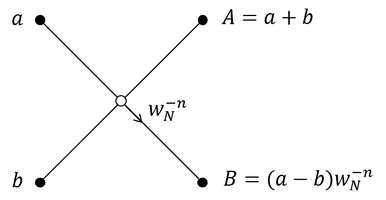

*Граф элементарной операции ("бабочки") алгоритма быстрого преобразования Фурье по основанию два с прореживанием по частоте*

После сказанного нетрудно построить граф всего алгоритма — он собирается из отдельных "бабочек" по тому же принципу, что и граф алгоритма с прореживанием по времени. Мы вновь приведём пример с $N=8$:

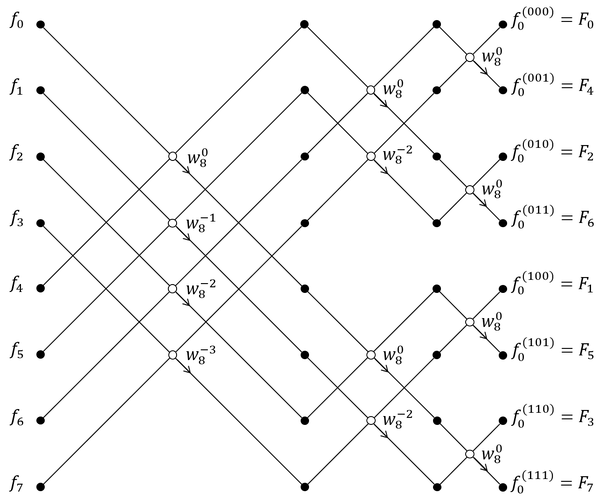

*Граф алгоритма быстрого преобразования Фурье по основанию два с прореживанием по частоте при $N=8$*

Как видим, построенный алгоритм в некотором смысле противоположен алгоритму БПФ с прореживанием по времени. В прежнем алгоритме осуществлялась сборка фурье-компонент путём последовательного **укрупнения** образуемых ими массивов. Иначе говоря, предполагалось, что тривиальные ДПФ (над "массивами" единичной длины) выполнены в самом начале и что алгоритм вычисляет искомые фурье-компоненты, отправляясь от результатов этих ДПФ. В "новом" же алгоритме принят обратный порядок операций: сначала происходит **измельчение** исходного массива (строятся всё более мелкие вспомогательные массивы), а в конце, когда получены "массивы" единичной длины, осуществляются тривиальные ДПФ (в действительности не требующие никаких операций). Таким образом, в "новом" алгоритме выполняется не сборка фурье-компонент, а подготовка к их "вычислению". Схема расчёта остаётся, по сути, той же, но обращается. Это видно и из сравнения двух графов: граф "нового" алгоритма получается из графа алгоритма БПФ с прореживанием по времени зеркальным отражением и обращением стрелок; дополнительно необходимо в подписях элементов заменить строчные буквы заглавными и наоборот: $f\leftrightarrow F$. Другими словами, для получения графа "нового" алгоритма нужно как бы прочитать граф прежнего алгоритма в обратном направлении (справа налево).

Легко заметить и ещё одно отличие "нового" алгоритма от БПФ с прореживанием по времени: перед началом расчёта не требуется выполнять никаких прореживаний, т.е. исходный порядок элементов является прямым (а не двоично-инверсным, как было раньше). С другой стороны, итоговый порядок фурье-компонент оказывается как раз двоично-инверсным (а не прямым). Отсюда следует, что для получения массива $F_q$ после завершения алгоритма необходимо переставить элементы с учётом правила двоичной инверсии. Дело обстоит так, как будто бы над массивом фурье-компонент $F_q$ (т.е. в пространстве частот) совершали последовательные прореживания. Поэтому говорят, что построенный алгоритм представляет собой **БПФ по основанию два с прореживанием по частоте**.

**Упражнение 6.** Как связаны друг с другом элементарные операции ("бабочки"), используемые в алгоритмах БПФ по основанию два с прореживанием по времени и с прореживанием по частоте?

Легко показать, что при заданном $N$ количество операций в алгоритме БПФ по основанию два с прореживанием по частоте оказывается тем же, что и в алгоритме с прореживанием по времени. Впрочем, это очевидно сразу из сравнения графов алгоритмов. Таким образом, оба рассмотренных алгоритма БПФ имеют асимптотическую сложность $O(N\log N)$. Повторим, что, по существу, речь идёт о разных вариантах одного и того же алгоритма, отличающихся лишь с технической точки зрения.

Программную реализацию алгоритма БПФ по основанию два с прореживанием по частоте мы предоставляем читателю (см. практическую задачу С).

### Быстрое преобразование Фурье в общем случае составного основания

Рассмотренные выше алгоритмы БПФ применимы в тех случаях, когда длина $N$ исходного массива значений $f_n$ равна степени двойки. Возникает естественный вопрос: как быть в других случаях, когда $N\neq 2^d$? Оказывается, что алгоритм БПФ можно построить при любом **составном** $N$. Основная идея остаётся прежней: **количество арифметических операций**, необходимых для вычисления фурье-компонент

$$F_q=\sum\limits_{n=0}^{N-1}f_nw_N^{-nq},$$

**значительно сокращается за счёт последовательных разбиений "большой" суммы на несколько "малых", т.е. за счёт усложнения схемы расчёта** (и, соответственно, структуры данных). С технической точки зрения алгоритм оказывается несколько более громоздким в силу произвольности $N$, и поэтому мы не будем разбирать его подробно. Вместо этого остановимся лишь на общих принципах.

Итак, предположим, что целое неотрицательное число $N$ является составным. Запишем его в виде произведения двух меньших чисел: $N=N_1N_2$. Тогда

$$N-1=N_1(N_2-1)+(N_1-1).$$

Учитывая это равенство, легко заметить, что любое целое число $n$, удовлетворяющее условию $0\leq n\leq N-1$, может быть представлено в виде

$$n=p_2N_1+s_1,$$

где $p_2$ и $s_1$ — тоже целые числа, причём

$$0\leq p_2\leq N_2-1,\qquad 0\leq s_1\leq N_1-1$$

(нижние индексы у величин $p_2$ и $s_1$ выбраны с учётом диапазонов их изменения: $p_2$ пробегает целые значения от $0$ до $N_2-1$, поэтому и несёт индекс "2"; аналогично для $s_1$). Значит, всякое суммирование по $n$ в пределах от $0$ до $N-1$ может быть заменено двойным суммированием — по $p_2$ и $s_1$:

$$\sum\limits_{n=0}^{N-1}=\sum\limits_{p_2=0}^{N_2-1}\sum\limits_{s_1=0}^{N_1-1}.$$

Производя в формуле для $F_q$ указанный переход от индекса $n$ к индексам $p_2$ и $s_1$, получаем:

$$F_q=\sum\limits_{p_2=0}^{N_2-1}\sum\limits_{s_1=0}^{N_1-1}f_{p_2N_1+s_1}w_N^{-(p_2N_1+s_1)q}.$$

Выполним теперь аналогичную подстановку для индекса $q$. Замечая, что

$$N-1=N_2(N_1-1)+(N_2-1),$$

полагаем

$$q=p_1N_2+s_2,\qquad 0\leq p_1\leq N_1-1,\qquad 0\leq s_2\leq N_2-1.$$

Тогда

$$F_{p_1N_2+s_2}=\sum\limits_{p_2=0}^{N_2-1}\sum\limits_{s_1=0}^{N_1-1}f_{p_2N_1+s_1}w_N^{-(p_2N_1+s_1)(p_1N_2+s_2)}=\sum\limits_{p_2=0}^{N_2-1}\sum\limits_{s_1=0}^{N_1-1}f_{p_2N_1+s_1}w_N^{-s_1s_2-p_2s_2N_1-s_1p_1N_2}.$$

Мы учли, что $N_1N_2=N$ и, следовательно, $w_N^{-p_1p_2N_1N_2}=1$. Меняя порядок суммирования и применяя правило понижения степени, получаем:

$$F_{p_1N_2+s_2}=\sum\limits_{s_1=0}^{N_1-1}\left[w_N^{-s_1s_2}\cdot\sum\limits_{p_2=0}^{N_2-1}f_{p_2N_1+s_1}w_N^{-p_2s_2N_1}\right]w_N^{-s_1p_1N_2}=\sum\limits_{s_1=0}^{N_1-1}\left[w_N^{-s_1s_2}\cdot\sum\limits_{p_2=0}^{N_2-1}f_{p_2N_1+s_1}w_{N_2}^{-p_2s_2}\right]w_{N_1}^{-s_1p_1}.$$

Для компактной записи этой формулы введём матрицы (двумерные массивы) размера $N_1\times N_2$:

$$m_{s_1p_2}\equiv f_{p_2N_1+s_1},\qquad 0\leq s_1\leq N_1-1,\qquad 0\leq p_2\leq N_2-1;$$

$$M_{p_1s_2}\equiv F_{p_1N_2+s_2},\qquad 0\leq p_1\leq N_1-1,\qquad 0\leq s_2\leq N_2-1.$$

Окончательно имеем:

$$M_{p_1s_2}=\sum\limits_{s_1=0}^{N_1-1}\left[w_N^{-s_1s_2}\cdot\sum\limits_{p_2=0}^{N_2-1}m_{s_1p_2}w_{N_2}^{-p_2s_2}\right]w_{N_1}^{-s_1p_1}.$$

Это и есть основная расчётная формула. Она очень похожа на формулу двумерного ДПФ, применяемого к матрице $m_{s_1p_2}$ для вычисления матрицы фурье-компонент $M_{p_1s_2}$ (мы приводили определение двумерного ДПФ выше):

$$M_{p_1s_2}=\sum\limits_{s_1=0}^{N_1-1}\sum\limits_{p_2=0}^{N_2-1}m_{s_1p_2}w_{N_1}^{-s_1p_1}w_{N_2}^{-p_2s_2}.$$

Отличие заключается только в том, что между двумя суммированиями "вставлены" умножения на поворачивающие множители $w_N^{-s_1s_2}$. Другими словами, весь расчёт проводится в три этапа:

* сначала выполняются $N_2$-точечные ДПФ (в количестве $N_1$) **по строкам** матрицы $m_{s_1p_2}$,

* затем происходит умножение получившихся фурье-компонент на поворачивающие множители $w_N^{-s_1s_2}$

* и, наконец, выполняются $N_1$-точечные ДПФ (в количестве $N_2$) **по столбцам** матрицы, построенной за два предыдущих этапа (в расчётной формуле элемент соответствующей матрицы с индексами $s_1$ и $s_2$ выписан в квадратных скобках).

Легко видеть, что для вычислений по такой схеме понадобится

$$N_2^2N_1+N_1N_2+N_1^2N_2=N_1N_2(N_2+1+N_1)=N(N_1+N_2+1)$$

операций с комплексными числами (эта оценка является асимптотической). Вычисление же ДПФ длины $N$ "в лоб" потребовало бы, как мы знаем, порядка $N^2$ операций. Мы имеем, таким образом, выигрыш примерно в

$$\frac{N^2}{N(N_1+N_2+1)}=\frac{N}{N_1+N_2+1}=\frac{N_1N_2}{N_1+N_2+1}\simeq \frac{N_1N_2}{N_1+N_2}$$

раз, причём очевидно, что с ростом $N$ выигрыш увеличивается.

Ясно, что если и числа $N_1$, $N_2$ оказались составными, то "дробление" ДПФ можно продолжать. Обычно в представлении $N=N_1N_2$ первый сомножитель выбирают простым, а второй — составным, так что на каждой следующей стадии алгоритма "дробятся" ДПФ, являвшиеся "внутренними" на предыдущей стадии. Пусть, например, $N=60$. Поскольку $60=5\times 12$, указанным методом сводим 60-точечное ДПФ к пятиточечным и 12-точечным; ДПФ второго типа окажется пять штук, и именно с выполнения этих ДПФ будет начинаться предложенный алгоритм (т.е. на первой стадии 12-точечные ДПФ окажутся "внутренними"). Но $12=3\times 4$, поэтому каждое из 12-точечных ДПФ тем же приёмом можно свести к трёхточечным и четырёхточечным ДПФ. В свою очередь, $4=2\times 2$, т.е. все "внутренние" ДПФ предыдущей стадии (четырёхточечные) заменяются совокупностями из двухточечных ДПФ (разумеется, с умножениями на поворачивающие множители между ними). Двухточечные же ДПФ без труда сводятся к тривиальным, как мы видели при рассмотрении БПФ по основанию два. Всю цепочку преобразований запишем так:

$$60=5\times 12=5\times (3\times 4)=5\times(3\times [2\times 2]).$$

Отметим, что для одного и того же $N$ можно указать несколько подобных представлений. Так, в случае $N=60$ можно было бы использовать следующее разложение вместо приведённого:

$$60=3\times(5\times [2\times 2]).$$

Хотя формально рассмотренные представления отличаются лишь перестановкой сомножителей, основанные на них алгоритмы получаются разными.

При реализации описанного способа расчёта ДПФ к стадиям расчёта по выведенной формуле должны быть добавлены этапы предварительной подготовки данных: перед каждой стадией алгоритм должен преобразовывать одномерные массивы в двумерные. Эту процедуру иногда называют **адресным тасованием**, и в разных реализациях алгоритма она может выполняться по-разному. Мы не будем на ней останавливаться (интересующиеся могут обратиться к книге Рабинера и Гоулда — см. список литературы).

Описанный общий алгоритм БПФ, применимый в случае составного $N$, часто называется **алгоритмом Кули—Тьюки**, по именам американских математиков, опубликовавших в 1965 г. статью с изложением его теоретических основ. Отметим, однако, что в действительности этот алгоритм был предложен ещё Гауссом в 1805 г. и неоднократно переоткрывался другими исследователями.

Если $N=2^d$, то от общей расчётной формулы можно перейти к формулам БПФ по основанию два. Положив $N_1=2$, $N_2=2^{d-1}$, получим алгоритм БПФ по основанию два с прореживанием по времени; если же, напротив, выбрать $N_1=2^{d-1}$, $N_2=2$, то получатся формулы БПФ по основанию два с прореживанием по частоте. Таким образом, рассмотренные выше алгоритмы БПФ являются частными случаями алгоритма Кули—Тьюки. Как мы видели, процедура адресного тасования в случае $N=2^d$ предельно упрощается: удаётся обойтись даже без двумерных массивов — достаточно лишь строить по данному одномерному массиву два других одномерных массива.

Отметим, что алгоритмы БПФ принадлежат к числу алгоритмов, построенных по принципу **"разделяй и властвуй"**. Суть всех алгоритмов этого типа состоит в том, что одна трудоёмкая задача рекурсивно сводится к решению нескольких более простых задач; процесс упрощения продолжается до тех пор, пока все подзадачи не окажутся элементарными. Характерной особенностью подобных алгоритмов является линейно-логарифмическая асимптотическая сложность $O(N\log N)$, где $N$ — характерный "размер" исходной задачи.

## Быстрое преобразование Фурье в Python


Встроенные реализации алгоритма БПФ можно найти в модуле ```fft``` библиотеки ```numpy``` ([документация](https://numpy.org/doc/stable/reference/routines.fft.html#module-numpy.fft)) и в одноимённом модуле библиотеки ```scipy``` ([документация](https://docs.scipy.org/doc/scipy/reference/fft.html)). Второй из этих модулей содержит больше функций; кроме того, функции ```scipy```, как правило, работают быстрее своих аналогов из ```numpy``` за счёт лучшей оптимизации. Поэтому на практике желательно пользоваться именно модулем ```scipy.fft``` . Мы приведём простейший пример использования некоторых функций из этого модуля. Предварительно сформулируем теорему, которая понадобится нам в дальнейшем.

**Теорема (Найквиста—Котельникова).** Пусть непрерывный сигнал не содержит гармоник с частотами выше $\omega_\text{max}$. Чтобы сигнал можно было *однозначно* восстановить по его значениям на равномерной сетке с шагом $\tau$, частота дискретизации $\Delta\omega=2\pi/\tau$ должна удовлетворять условию $\Delta\omega>2\omega_\text{max}$, или, эквивалентно, $\omega_\text{max}<\pi/\tau\equiv\omega_\text{N}$, где $\omega_\text{N}$ — *частота Найквиста*.

Частоты, отличающиеся на целое число шагов $\Delta\omega$, в результате дискретизации дают одинаковые отсчёты:

$$\omega\cong\omega+m\cdot\Delta\omega,\qquad m\in\mathbb{Z},$$

поскольку

$$e^{i(\omega+m\cdot\Delta\omega)t_n}=e^{i\omega t_n},\qquad t_n=n\tau,\qquad n\in\mathbb{Z}.$$

Поэтому гармоника с частотой выше частоты Найквиста $\omega_\text{N}$ после дискретизации может оказаться неотличимой от гармоники с более низкой частотой. Это явление называется **алиасингом** (от англ. aliasing — наложение).

Перед переходом к практической реализации преобразования Фурье

## Простейший фурье-анализ

Пусть некоторый **действительный** сигнал $f=f(t)$ представляет собой сумму $k$ гармонических сигналов:

$$f(t)=\sum\limits_{i=1}^kA_i\sin(\omega_i t+\varphi_i),$$

где $A_i$, $\omega_i$ и $\varphi_i$ — соответственно амплитуда, частота и начальная фаза $i$-й составляющей сигнала. Будем считать, что параметры каждого из $k$ сигналов неизвестны. Требуется по суммарному сигналу $f=f(t)$ восстановить частоты отдельных его составляющих, т.е. провести **спектральный анализ сигнала**.

Будем считать, что сигнал рассматривается на промежутке $[0,T)$, и введём равномерную сетку из $N$ узлов:

$$t_n=n\tau,\qquad \tau=\frac{T}{N},\qquad n=0,1,\ldots,N-1.$$

Шаг сетки по частоте равен

$$\Delta\omega=\frac{2\pi}{T}.$$

Частоты ДПФ определяются формулой

$$\omega_q=\begin{cases}q\,\Delta\omega, & 0\leq q\leq \left\lfloor (N-1)/2\right\rfloor,\\[4pt]
(q-N)\,\Delta\omega, & \left\lceil N/2\right\rceil\leq q\leq N-1.\end{cases}$$

Таким образом, вторая половина массива коэффициентов ДПФ соответствует отрицательным частотам. Напишем функцию для построения временной и частотной сеток:

In [25]:
import numpy as np
import scipy as sp

def grids(T: float, N: int):
    tau = T / N

    t = tau * np.arange(N)
    omega = 2*np.pi * sp.fft.fftfreq(N, d=tau)

    return t, omega

Напишем функцию ```sum_sin```, создающую массив $f_n$ значений сигнала $f=f(t)$ в узлах сетки $t_n$. Амплитуду $A_i$ и начальную фазу $\varphi_i$ каждой гармонической составляющей будем выбирать случайными (для определённости полагаем, что $A_i\in[0,10]$). Частоты отдельных составляющих будем задавать в виде массива ```freqs``` (он тоже будет заполняться случайными числами, но его мы для наглядности создадим отдельно, вне функции ```sum_sin```):

In [26]:
def sum_sin(t: np.ndarray, freqs: np.ndarray):
    amplitudes = np.random.uniform(0, 10, freqs.shape[0])
    amplitudes = amplitudes[:, np.newaxis] * np.ones(t.shape[0])

    shifts = np.random.uniform(0, 2*np.pi, freqs.shape[0])
    shifts = shifts[:, np.newaxis] * np.ones(t.shape[0])

    frequencies = freqs[:, np.newaxis] * t

    sins = amplitudes * np.sin(frequencies + shifts)

    return np.sum(sins, axis=0)

Для первой демонстрации выберем $T=2\pi$ и $N=50$. В этом случае шаг частотной сетки равен $\Delta\omega=2\pi/T=1$, а частота Найквиста равна $\omega_\text{N}=25$. Частоты полного ДПФ имеют вид $0,1,\ldots,24,-25,-24,\ldots,-1$. Чтобы избежать алиасинга и получить на графике ровно пять различимых ненулевых частот, выберем $k=5$ неповторяющихся целочисленных частот из множества $\{1,2,\ldots,24\}$. Нулевую частоту исключим только для наглядности: она соответствует постоянной составляющей сигнала. По сгенерированным частотам создадим массив $f_n$ значений сигнала $f=f(t)$ и изобразим этот сигнал на графике:

In [27]:
T = 2*np.pi
N = 50

t_grid, omega_grid = grids(T, N)
freqs = np.random.choice(np.arange(1, N // 2), size=5, replace=False)

f = sum_sin(t_grid, freqs)

In [28]:
import matplotlib.pyplot as plt

def plot_signal(t_grid: np.ndarray, f: np.ndarray):
    fig, ax = plt.subplots()
    ax.plot(t_grid, f, lw=0.75, c='r')

    plt.title("Сигнал $f=f(t)$")
    plt.xlabel("$t$")
    plt.ylabel("$f$")

    plt.show()

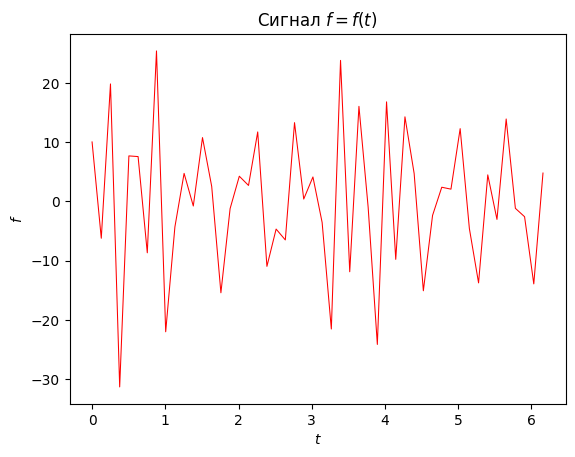

In [29]:
plot_signal(t_grid, f)

Перейдём к спектральному анализу. Очевидно, что для выделения частот отдельных гармонических составляющих из суммарного сигнала $f=f(t)$ достаточно выполнить ДПФ этого сигнала. В самом деле, формулу обратного ДПФ

$$f_n=\frac{1}{N}\sum\limits_{q=0}^{N-1}F_qw_N^{qn}\equiv\frac{1}{N}\sum\limits_{q=0}^{N-1}F_q\exp\bigg(i\,\frac{2\pi q}{N}\,n\bigg)=\frac{1}{N}\sum\limits_{q=0}^{N-1}F_q\exp(i\omega_q t_n)$$

можно рассматривать как разложение сигнала $f=f(t)$, подвергнутого дискретизации, в сумму комплексных гармоник с частотами $\omega_q$. Коэффициент при $q$-й комплексной гармонике в этой сумме равен $F_q/N$, а не $F_q$. Модуль и аргумент $F_q$ определяют соответственно величину вклада и фазу этой гармоники. Поэтому для определения частот составляющих сигнала следует вычислить ДПФ и проанализировать положения пиков модулей коэффициентов $|F_q|$.

Для расчёта ДПФ воспользуемся функцией ```fft``` из уже упомянутого модуля ```fft``` библиотеки ```scipy``` ([документация](https://docs.scipy.org/doc/scipy/reference/generated/scipy.fft.fft.html#scipy.fft.fft)). Она вычисляет одномерное $N$-точечное ДПФ либо с помощью алгоритма Кули—Тьюки, либо — при плохо факторизуемых $N$ — с помощью алгоритма Блюстейна (см. книгу Рабинера и Гоулда из списка литературы). Функция ```fft``` принимает на вход массив значений $f_n$ и выдаёт массив фурье-компонент $F_q$. При вызове функции дополнительно может быть задан необязательный аргумент ```n``` — длина искомого массива $F_q$. Если она меньше длины входного массива $f_n$, то последний будет укорочен, если больше — дополнен нулями. Полезно знать о существовании ещё одного необязательного аргумента ```norm```, позволяющего при необходимости изменять нормировку прямого и обратного ДПФ. Если ```norm = "backward"``` (значение по умолчанию), то в прямом преобразовании отсутствует деление на $N$, а в обратном преобразовании оно присутствует (т.е. используется та же нормировка, что и в тексте семинара). Выбор ```norm = "forward"``` меняет нормировку на противоположную (деление на $N$ переносится в прямое ДПФ). Если же ```norm = "ortho"```, то и прямое, и обратное ДПФ будут содержать деление на $\sqrt{N}$.

В нашем случае для расчёта фурье-компонент достаточно следующего простого вызова:



In [30]:
import scipy as sp

F = sp.fft.fft(f)

Визуализируем зависимость модулей коэффициентов ДПФ $|F_q|$ от соответствующих им частот $\omega_q$. Предварительно следует учесть, что величина $|F_q|$ не является амплитудой исходной действительной гармоники.

При стандартной нормировке `scipy.fft` (`norm="backward"`) для гармоники с амплитудой $A_i$, точно попавшей во внутренний узел частотной сетки ДПФ,

$$|F_q|=\frac{NA_i}{2},\qquad A_i=\frac{2|F_q|}{N}.$$

Здесь внутренним называется узел с номером $q\ne 0$ и, при чётном $N$, $q\ne N/2$. Формула приведена для рассматриваемого здесь простейшего случая. Более общие ситуации требуют дополнительных оговорок, которые в рамках этого семинара обсуждаться не будут. Попадание в узел частотной сетки означает, что на интервале наблюдения укладывается целое число периодов гармоники.

Действительно, по формуле Эйлера вещественная гармоника представляется в виде суммы двух комплексных гармоник:

$$A_i\sin\left(\frac{2\pi qn}{N}+\varphi_i\right)=\frac{A_i}{2i}e^{i(2\pi qn/N+\varphi_i)}-\frac{A_i}{2i}e^{-i(2\pi qn/N+\varphi_i)}.$$

Эти комплексные гармоники имеют частоты $\omega_i$ и $-\omega_i$, а коэффициент при каждой из них по модулю равен $A_i/2$. Если частота совпадает с узлом сетки ДПФ, суммирование по $N$ отсчётам даёт дополнительный множитель $N$, поэтому модуль каждого из двух коэффициентов равен $NA_i/2$.

Для построения графика типа `stem` нормируем модули коэффициентов на их максимальное значение. Такая нормировка удобна для определения частот по положениям пиков, но после неё восстановить абсолютные амплитуды гармоник уже нельзя:

In [31]:
def plot_spectrum(omega_grid: np.ndarray, F: np.ndarray):
    F = np.abs(F)
    F = F / np.max(F)

    fig, ax = plt.subplots()
    ax.stem(omega_grid, F, linefmt='b-')

    plt.title("Спектр сигнала $f=f(t)$")
    plt.xlabel("$\\omega$")
    plt.ylabel("$|F|\\,/\\,|F|_\\text{max}$")

    plt.show()

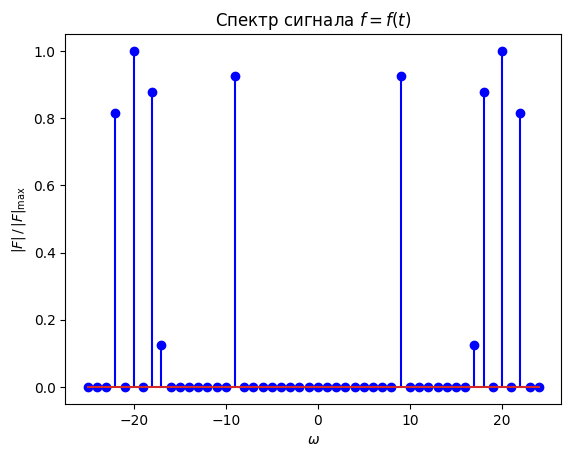

In [32]:
plot_spectrum(
    sp.fft.fftshift(omega_grid),
    sp.fft.fftshift(F)
)

После одновременного применения функции ```fftshift``` к частотной сетке и коэффициентам ДПФ график получился симметричным относительно нулевой частоты. Это соответствует свойству ДПФ действительного сигнала: $F_{N-q}=F_q^*$, а значит, $|F_{N-q}|=|F_q|$. Чтобы в подобных случаях не строить половину спектра, не содержащую независимой информации, можно использовать вместо функции ```fft``` функцию ```rfft``` ([документация](https://docs.scipy.org/doc/scipy/reference/generated/scipy.fft.rfft.html#scipy.fft.rfft)). Она рассчитана на действительнозначные массивы и выдаёт $N/2+1$ фурье-компоненту при чётном $N$ или $(N+1)/2$ компонент при нечётном $N$. Следует иметь в виду, что при подаче на вход функции ```rfft``` комплекснозначного массива исключение не возбуждается: мнимые части элементов просто игнорируются.

Строим график неотрицательной половины спектра:

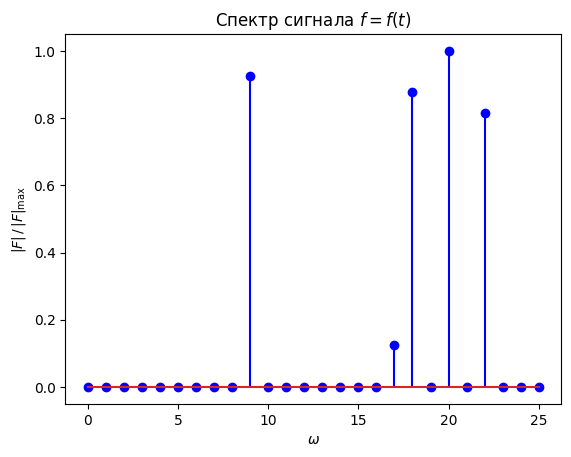

In [33]:
F = sp.fft.rfft(f)

tau = T / N
omega_rfft = 2*np.pi * sp.fft.rfftfreq(N, d=tau)

plot_spectrum(omega_rfft, F)

По положениям пиков нормированных модулей коэффициентов $|F_q|$ легко восстанавливаются частоты гармонических составляющих входного сигнала. Поскольку в этой демонстрации выбраны различные ненулевые частоты строго ниже частоты Найквиста, каждому пику однозначно соответствует элемент массива ```freqs```. Отрицательные частоты на графике отсутствуют: функция ```rfft``` не возвращает сопряжённую половину спектра, поскольку она не содержит новой информации. Сравним частоты, найденные по графику, с частотами из массива ```freqs```, по которым был построен сигнал:

In [34]:
freqs

array([18, 17, 22,  9, 20])

Для массива, полученного с помощью функции ```rfft```, соответствующая частотная сетка строится функцией ```rfftfreq``` ([документация](https://docs.scipy.org/doc/scipy/reference/generated/scipy.fft.rfftfreq.html#scipy.fft.rfftfreq)). Она принимает длину массива $N$ и шаг временной сетки $\tau=T/N$, а возвращает частоты в циклах на единицу времени. Чтобы получить угловые частоты $\omega_q$, результат нужно умножить на $2\pi$:

In [35]:
tau = T / N
omega_rfft = 2*np.pi * sp.fft.rfftfreq(N, d=tau)

omega_rfft

array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.,
       13., 14., 15., 16., 17., 18., 19., 20., 21., 22., 23., 24., 25.])

При чётном $N$ функция ```rfftfreq``` возвращает $N/2+1$ неотрицательную частоту: от нуля до частоты Найквиста включительно. Умножение на $2\pi$ переводит обычные частоты, измеряемые в циклах на единицу времени, в угловые частоты, измеряемые в радианах на единицу времени.

Для полного ДПФ используется функция ```fftfreq``` ([документация](https://docs.scipy.org/doc/scipy/reference/generated/scipy.fft.fftfreq.html#scipy.fft.fftfreq)). Она возвращает частотную сетку длины $N$, причём частоты располагаются в порядке $0,\Delta\omega,\ldots,-2\Delta\omega,-\Delta\omega$. Чтобы расположить их по возрастанию, применяется функция ```fftshift``` ([документация](https://docs.scipy.org/doc/scipy/reference/generated/scipy.fft.fftshift.html#scipy.fft.fftshift)). Эту функцию необходимо применять одновременно к частотной сетке и к массиву коэффициентов ДПФ:

In [36]:
omega_fft = (2*np.pi * sp.fft.fftshift(sp.fft.fftfreq(N, d=tau)))

np.allclose(omega_fft, sp.fft.fftshift(omega_grid))

True

В приведённой выше демонстрации частоты гармонических составляющих специально выбирались из частотной сетки ДПФ. Поэтому каждой действительной гармонике соответствовала пара ненулевых фурье-компонент с частотами $\omega_i$ и $-\omega_i$; функция `rfft` возвращала только компоненту с неотрицательной частотой.

Если частота гармоники не совпадает с узлом частотной сетки, её вклад уже не сосредоточен в одной фурье-компоненте. Из-за конечной продолжительности наблюдения он распределяется по многим, а в общем случае — по всем частотным отсчётам. Это явление называется **спектральной утечкой**. Наибольшие значения модулей фурье-компонент обычно наблюдаются вблизи исходной частоты, однако кроме основного максимума возникают боковые лепестки. Продемонстрируем спектральную утечку на примере:

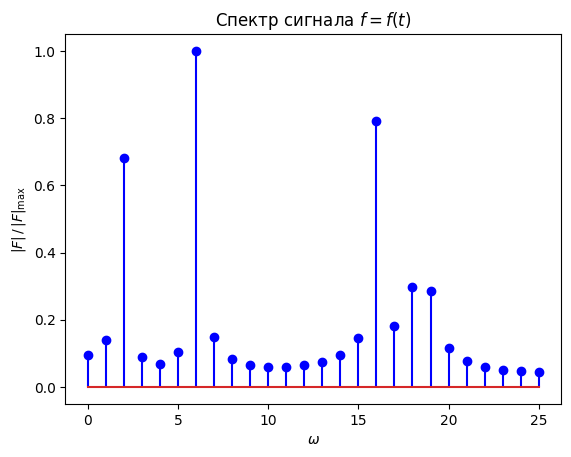

In [37]:
omega_nyq = np.pi / tau
freqs = np.random.uniform(0, omega_nyq, 5)
f = sum_sin(t_grid, freqs)

F = sp.fft.rfft(f)
plot_spectrum(omega_rfft, F)

In [38]:
freqs

array([ 6.11693796, 18.44433544, 15.71102598,  1.85703579, 16.24478531])

При выборе параметров дискретизации $T$ и $N$ важно различать два эффекта. Шаг временной сетки $\tau=T/N$ определяет частоту Найквиста:

$$\omega_\text{N}=\frac{\pi}{\tau}=\frac{\pi N}{T}.$$

Чтобы избежать алиасинга, необходимо выбирать достаточный малый шаг $\tau$, т.е. такой, чтобы выполнялось условие $\omega_\text{max}<\pi/\tau$. При фиксированном $T$ увеличение $N$ уменьшает $\tau$ и расширяет диапазон частот, которые можно однозначно восстановить, но не изменяет шага частотной сетки

$$\Delta\omega=\frac{2\pi}{T}.$$

Поэтому для улучшения частотного разрешения необходимо увеличивать продолжительность наблюдения $T$. Если при этом требуется сохранить прежний шаг $\tau$, число отсчётов $N$ также следует увеличить. В следующем примере рассмотрим выделение гармонических составляющих из сигнала с шумом.

Сгенерируем один набор из $k=20$ гармоник и одну реализацию шума. Все частоты выберем строго ниже частоты Найквиста. Далее будем менять число гармоник $k$. При изменении $k$ в сигнал будут включаться первые $k$ гармоник из зафиксированного набора, а шум будет оставаться неизменным.

In [39]:
N_noise = 10**3
T_noise = 10
k_max = 20

tau_noise = T_noise / N_noise
t_noise = tau_noise * np.arange(N_noise)
omega_nyq_noise = np.pi / tau_noise

# один раз генерируем параметры гармоник и реализацию шума
rng = np.random.default_rng(42)
freqs_noise = rng.uniform(0, omega_nyq_noise, k_max)
amplitudes_noise = rng.uniform(0, 10, k_max)
shifts_noise = rng.uniform(0, 2*np.pi, k_max)
fixed_noise = rng.normal(0, 5, N_noise)

harmonics_noise = (amplitudes_noise[:, np.newaxis] *
    np.sin(freqs_noise[:, np.newaxis] * t_noise + shifts_noise[:, np.newaxis]))

def plot_spectrum_noise(k: int):
    # меняется только число гармоник, их параметры и шум зафиксированы
    f = np.sum(harmonics_noise[:k], axis=0) + fixed_noise

    # фурье-анализ
    F = sp.fft.rfft(f)
    omega_rfft = 2*np.pi * sp.fft.rfftfreq(N_noise, tau_noise)
    F = np.abs(F)
    F = F / np.max(F)

    # построение графика
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.plot(t_noise, f, c='r', linewidth=1)
    ax1.set_title("Сигнал с шумом")
    ax1.set_xlabel("$t$")
    ax1.set_ylabel("$f$")

    ax2.plot(omega_rfft, F, c='b', linewidth=1)
    ax2.set_title("Спектр сигнала с шумом")
    ax2.set_xlabel("$\\omega$")
    ax2.set_ylabel("$|F|\\,/\\,|F|_\\text{max}$")

    plt.show()

In [40]:
from ipywidgets import interact, IntSlider

# ползунок для интерактивного графика (виджета)
k_w = IntSlider(min=1, max=k_max, value=5)

interact(plot_spectrum_noise, k=k_w);

interactive(children=(IntSlider(value=5, description='k', max=20, min=1), Output()), _dom_classes=('widget-int…

Параметр $k$ задаёт число гармонических составляющих, входящих в сигнал. При увеличении $k$ график сигнала во временной области становится более сложным, а в его спектре появляются новые максимумы вблизи частот добавленных гармоник. Шум при этом создаёт фоновый уровень спектра, однако достаточно сильные гармоники остаются хорошо различимыми. Поскольку их частоты в общем случае не совпадают с узлами частотной сетки, вместо одиночных пиков могут возникать группы близких ненулевых отсчётов вследствие спектральной утечки. Кроме того, спектр при каждом значении $k$ нормируется на свой максимум, поэтому высоты ранее появившихся пиков могут визуально изменяться.

В модуле ```scipy.fft``` имеются и другие функции, полезные при фурье-анализе (например, готовые реализации двумерного и $n$-мерного ДПФ). Ознакомиться с ними читатель сможет самостоятельно по документации, ссылка на которую была приведена выше.

---

# Практические задачи

## Задача A

1. Реализовать метод скалярной **трёхточечной** прогонки решения СЛАУ $\textbf{A}\textbf{x}=\textbf{f}$ с **трёхдиагональной** матрицей $\textbf{A}$ порядка $n$. Программа должна содержать две функции: ```tridiagonal_kernel``` и ```tridiagonal_alg```.

   Первая функция представляет собой "вычислительное ядро" метода: она принимает на вход задающие СЛАУ массивы $\alpha_i$, $\beta_i$, $\gamma_i$ и $f_i$, выполняет собственно прогонку (прямую и обратную) и выдаёт ответ в виде массива $x_i$.

   Вторая функция служит "обёрткой" для вычислительного ядра: она принимает на вход матрицу СЛАУ $\textbf{A}$ (в виде двумерного массива) и вектор правой части $\textbf{f}$, проверяет трёхдиагональность матрицы, выполнение условия строгого диагонального преобладания и только при положительном результате обеих проверок вызывает "вычислительное ядро" (в противном случае должны возбуждаться исключения).

2. Написать аналогичную программу, реализующую метод скалярной **пятиточечной** прогонки для решения СЛАУ $\textbf{A}\textbf{x}=\textbf{f}$ с **пятидиагональной** матрицей $\textbf{A}$ порядка $n$. Воспользоваться вычислительными формулами, выведенными при решении упражнения 2 (см. выше).

3. Продемонстрировать, что оба варианта метода прогонки (как для трёхдиагональной матрицы, так и для пятидиагональной матрицы) имеют линейную вычислительную сложность.

*Примечание.* Заготовки программ, реализующих трёхточечную и пятиточечную прогонки, понадобятся нам в следующем семестре.

## Задача B

1. Написать программу для построения **естественного** кубического интерполяционного сплайна $S_3=S_3(x)$ (с единичным дефектом) на равномерной сетке из $n+1$ узлов, введённой на отрезке $[a,b]$ (граничные узлы сетки совпадают с граничными точками отрезка). Входные данные — массивы $x_i$ и $f_i$, задающие таблицу значений неизвестной функции-оригинала $f=f(x)$. Программа должна поддерживать

   * вывод любого из $4n$ коэффициентов сплайна по номеру его "куска" $i$ ($1\leq i\leq n$) и степени $p$ ($0\leq p\leq 3$) в выражении $(x-x_{i-1})^p$, при котором стоит этот коэффициент,

   * печать любого "куска" сплайна (по его номеру $i$) в виде формулы ```sympy```,

   * однократное и двукратное дифференцирование сплайна, т.е. построение сплайнов $S_3'=S_3'(x)$ и $S_3''=S_3''(x)$,

   * вычисление значений сплайна $S_3$ и двух его производных $S_3'$, $S_3''$ в любой точке, принадлежащей отрезку $[a,b]$,

   * вывод графиков сплайна и его производных.

   Наиболее оптимальный формат реализации — пользовательский класс ```MySpline```.

2. С помощью написанной программы построить сплайны для следующих функций:

   $$f(x)=e^{x},\quad f(x)=x^{4},\quad f(x)=\frac{1}{1+25x^{2}}.$$

   Во всех трёх случаях использовать равномерную сетку из $n+1$ узлов на отрезке $[-1,1]$.

3. Сравнить результаты сплайн-интерполяции с результатами кусочно-линейной интерполяции на той же сетке (см. задачу А из семинара 6).

4. Построить сплайн по значениям какого-нибудь кубического многочлена, заданного на отрезке $[a,b]$. Воспроизводит ли сплайн этот многочлен? То же для многочленов первой и второй степеней.


## Задача C


Предложить программную реализацию алгоритма быстрого преобразования Фурье по основанию два с прореживанием **по частоте**. Программа должна принимать на вход массив значений функции $f_n$ длины $N=2^d$ (при другой длине массива должно возбуждаться исключение) и выдавать массив фурье-компонент $F_q$ (**в правильном порядке:** от нулевой компоненты к компоненте с номером $N-1$). Проверить корректность программы, запустив её при одних и тех же входных данных вместе с "наивной" реализацией ДПФ. Убедиться, что написанная программа выдерживает "экстремальный" тест с $N=2^{14}$.

## Задача D


Написать программу для быстрого умножения многочленов, основанную на алгоритме БПФ. Программа должна принимать на вход массив $p_n$ длины $k+1$, содержащий коэффициенты многочлена $P_k(x)$ степени $k$, и аналогичный массив $q_n$ с коэффициентами многочлена $Q_l(x)$ степени $l$. Выходные данные — массив коэффициентов $r_n$ многочлена-произведения $P_k(x)\cdot Q_l(x)$. Во всех массивах коэффициенты многочленов должны задаваться в удобном для чтения порядке (от коэффициента при старшем члене к свободному множителю). Программа должна поддерживать умножение многочленов **любых** степеней (а не только многочленов, у которых количество коэффициентов равно $2^d$). При этом использовать встроенные реализации БПФ запрещается.

# Литература и другие источники

## К части первой

**Видеозаписи:**

1. Вычислительная математика — лекция 11. Лектор — Е.Н. Аристова. [Ссылка](https://www.youtube.com/live/Kt2tcbBvudA?si=AzjMvzA-LbyRxWkN&t=101) (YouTube).

2. Вычислительная математика — лекция 10. Лектор — А.В. Чикиткин. [Ссылка](https://youtu.be/7bcn_braq4g?si=OXLPB3sgyD88Gvue) (YouTube).

**Рекомендуемая литература (с комментариями):**

Сведения об интерполяции сплайнами можно найти в следующих книгах:

1. *Н.Н. Калиткин, Е.А. Альшина. Численный анализ.* Первый том учебника "Численные методы" (в двух книгах) — пункт 4.2 главы 4 (стр. 147—153). Дополнительные сведения можно найти в пункте 5.5 главы 5 (стр. 193—202). Следует иметь в виду, что название типов интерполяционных сплайнов, приведённые в этой книге, несколько отличаются от общепринятых.

2. *А.А. Амосов, Ю.А. Дубинский, Н.В. Копченова. Вычислительные методы для инженеров* — параграф 11.11, стр. 333—339.

3. *А.А. Самарский, А.В. Гулин. Численные методы* — параграф 4 главы 3 (стр. 140—148).

4. *К. де Бор. Практическое руководство по сплайнам.* Первые две главы посвящены глобальной алгебраической интерполяции. Интерполяция кубическими сплайнами рассматривается (наряду с другими способами интерполяции кубическими многочленами) в главе IV (стр. 47—57).

5. *В.Л. Макаров, В.В. Хлобыстов. Сплайн-аппроксимация функций.* Материал по теме семинара изложен в параграфах 1.1 и 1.2 (стр. 4—16).

6. *Ю.С. Завьялов, Б.И. Квасов, В.Л. Мирошниченко. Методы сплайн-функций* — введение (стр. 9—14), параграф 1 главы I (стр. 15—18), параграф 1 главы III (стр. 96—101). В добавлении (стр. 333—345) кратко изложены методы скалярной трёхточечной и скалярной пятиточечной прогонок.

Дополнительная литература:

7. *Р.С. Пастушков. Задачи и упражнения по вычислительной математике. V семестр. Решения, указания, ответы.* Напомним, что это пособие есть в библиотеке МФТИ. В электронном виде его легче всего скачать с сайта О.А. Пырковой (см. ниже).

**Сайты и другие электронные ресурсы:**

1. Персональный сайт преподавателя МФТИ О.А. Пырковой. Содержит много полезных материалов по различным математическим курсам МФТИ. Страница с материалами осеннего семестра по вычислительной математике: [ссылка](https://www.pyrkovaoa-fizteh.ru/консультация-вычм-5/).

2. Scientific Python Lectures. Очень полезный ресурс, представляющий собой учебник по научному программированию на языке Python. Представлено много различных библиотек. Есть pdf-версия. Все материалы на английском языке. [Ссылка.](https://lectures.scientific-python.org/)

3. Python Programming And Numerical Methods: A Guide For Engineers And Scientists. Прекрасный сайт, представляющий собой электронную версию одноимённой книги по научному программированию на Python. Исключительно подробное изложение с многочисленными примерами. [Ссылка.](https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/Index.html)

## К части второй



**Рекомендуемая литература (с комментариями):**

1. *Л. Рабинер, Б. Гоулд. Теория и применение цифровой обработки сигналов.* ДПФ и его основные свойства рассмотрены в параграфах 2.21 и 2.22 главы второй (стр. 62—72). Алгоритмам БПФ посвящена глава шестая (для наших нужд достаточно материала параграфов 6.1—6.9, стр. 394—421). Подробнее, чем в других источниках, рассмотрен алгоритм Кули—Тьюки в общем случае составного основания (параграф 6.8). Приведены краткие сведения об алгоритме Блюстейна, применяемом вместо алгоритма Кули—Тьюки при плохо факторизуемых $N$ (параграф 6.16, стр. 433—435).

2. *Р. Блейхут. Быстрые алгоритмы цифровой обработки сигналов.* БПФ рассмотрено в главе четвёртой. Алгоритму Кули—Тьюки (в том числе по основанию два) посвящены первые два параграфа этой главы (стр. 128—140). В отличие от предыдущего источника, сначала рассмотрен случай произвольного составного основания, а затем — случай БПФ по основанию два. Недостатки: предварительные сведения о ДПФ не выделены в отдельный параграф и встречаются фрагментами в первой и второй главах (стр. 28—29, стр. 31—32, стр. 45—46, стр. 77—78); при изложении общего алгоритма Кули—Тьюки допущена опечатка в основной расчётной формуле.

3. *Г. Нуссбаумер. Быстрое преобразование Фурье и алгоритмы вычисления свёрток.* БПФ посвящена глава 4 (стр. 75—102), в которой очень компактно изложены все основные теоретические положения. Необходимые вспомогательные сведения содержатся в предыдущих главах. На элементарном уровне рассмотрен не затронутый в тексте семинара вопрос об ошибках округления в алгоритме БПФ (стр. 89—91).

4. *В.П. Кандидов, С.С. Чесноков, С.А. Шленов. Дискретное преобразование Фурье.* Учебное пособие, изданное в МГУ. Заслуживают внимания главы 5 (стр. 63—70) и 6 (стр. 71—86), последняя из которых посвящена готовым программным реализациям алгоритмов БПФ на разных языках программирования. [Ссылка на пособие.](http://ovf.phys.msu.ru/upload/iblock/ca6/Дискретное%20преобразование%20Фурье.pdf)

Дополнительная литература:

5. *J.W. Cooley, J.W. Tukey. An algorithm for the machine calculation of complex Fourier series.* Оригинальная статья Кули и Тьюки 1965 г., в которой изложен переоткрытый ими алгоритм БПФ. [Ссылка на полный текст.](https://pubs.ams.org/journals/mcom/1965-19-090/S0025-5718-1965-0178586-1/home.html)

**Сайты и другие электронные ресурсы:**

1. *Быстрое преобразование Фурье за $O(N\log N)$. Применение к умножению двух полиномов или длинных чисел* — страница, посвящённая преобразованию Фурье, на сайте "MAXimal". Приведены примеры программ БПФ по основанию два на языке C++. Рассмотрено применение БПФ в качестве алгоритма быстрого умножения полиномов. [Ссылка.](http://e-maxx.ru/algo/fft_multiply)

2. *Понимание алгоритма БПФ* — переводная статья на портале "Хабр". [Ссылка](https://habr.com/ru/companies/otus/articles/449996/) на статью. [Оригинал](https://jakevdp.github.io/blog/2013/08/28/understanding-the-fft/) (на английском языке).

3. *Быстрое умножение многочленов при помощи преобразования Фурье — это просто*. Ещё одна статья на портале "Хабр". Рассмотрен алгоритм БПФ и его применение в задаче о быстром умножении многочленов. Есть примеры кода на C++. [Ссылка.](https://habr.com/ru/articles/113642/)

# Контрольные вопросы

## К части первой

1. Применима ли глобальная алгебраическая интерполяция для высокоточного приближения функций? Почему?
2. В чём заключается идея локальной алгебраической интерполяции?
3. Что такое сплайн? интерполяционный сплайн?
4. Дайте определение дефекта сплайна. Какой смысл имеет дефект сплайна? Поясните ответ примерами.
5. Опишите процедуру построения **естественного** кубического интерполяционного сплайна (с единичным дефектом). Сколькими коэффициентами он задаётся? Какие условия накладываются на эти коэффициенты? Каков физический смысл естественного сплайна?
6. Приведите примеры интерполяционных сплайнов других типов. Чем они отличаются? В каких случаях разумно использовать интерполяционный сплайн того или иного типа?
7. В каких случаях применяется метод прогонки решения СЛАУ?
8. Раскройте суть метода прогонки. Выпишите расчётные формулы метода.
9. В чём заключается преимущество применения метода прогонки для СЛАУ с трехдиагональной матрицей перед применением метода последовательных исключений Гаусса (для матриц общего вида)?
10. При каком условии метод прогонки устойчив и корректен?
11. Выпишите оценки погрешностей сплайн-интерполяции, справедливые при приближении функции-оригинала $f\in C^4[a,b]$ естественным кубическим сплайном.

## К части второй

12. Написать покомпонентные формулы прямого и обратного ДПФ (в одномерном случае).
13. Написать формулы прямого и обратного ДПФ в векторно-матричном виде.
14. Пусть имеется программа, осуществляющая ДПФ над массивом $f_n$ и выдающая результат — массив фурье-компонент $F_q$. Нужно ли писать отдельную программу для обратного ДПФ (нахождения $f_n$ по $F_q$)?
15. В чём заключается свойство периодичности фурье-компонент $F_q$?
16. Пусть последовательность $f_n$ вещественнозначна. Что можно сказать о её фурье-компонентах $F_q$?
17. Как определяется двумерное ДПФ?
18. Какова асимптотическая сложность вычисления ДПФ по определению?
19. В чём суть алгоритма БПФ по основанию два с прореживанием по времени?
20. В чём состоит правило двоичной инверсии и для чего оно используется?
21. Как называется элементарная операция алгоритма БПФ по основанию два с прореживанием по времени? В чём она заключается?
22. Построить граф алгоритма БПФ по основанию два с прореживанием по времени для случая массива из восьми элементов.
23. Чему равна асимптотическая сложность алгоритма БПФ по основанию два с прореживанием по времени?
24. Чем алгоритм БПФ по основанию два с прореживанием по частоте отличается от аналогичного алгоритма с прореживанием по времени? Что общего у этих алгоритмов?
25. По какому принципу строятся алгоритмы БПФ в общем случае составного числа элементов в массиве? Как называются алгоритмы этого типа?